# Connecting Platynereis morphology to spatial expression

**A worked exploration of your actual files — 2 October 2026.** Start at the top and run in order in the `MorphoFeats_dev` environment. This is a new notebook; `joint_projection_test.ipynb` is preserved.

The useful first question is **“Does morphology contain information about the spatial gene calls, beyond where the cell sits?”** A second, different question is **“Does adding expression improve a joint description or prediction of manually annotated cell types?”** These need separate experiments: a joint vector already contains expression, so it cannot demonstrate prediction of expression *from morphology*.

What the file audit established:

* All three `spatial_expr_df_binarized.tsv` files are byte-identical: **11,382 nuclei × 201 XLOC features**, with binary values, unique IDs and no missing entries. Five rows have no positive gene calls. `XLOC-019991` (`Tan`) is constant zero.
* The nonzero nucleus mappings link these nuclei **one-to-one** to all 11,382 cells in both the DINO table from your notebook and the original **480-dimensional MorphoFeatures** table. The latter `.npy` already contains IDs in column 0; it is **not** an ID-free array of every segmented cell.
* scLocator's broad and high-resolution outputs use the **same expression input and same 31,121-cell, 6-dpf RNA reference**. They offer 15 broad or 274 fine biological reference categories, plus two synthetic profiles: `zero` and `autofluorescence`. “High resolution” here means annotation detail, not imaging resolution.
* The RNA reference cells have sequencing barcodes. They are **not the EM cells**, and RNA batch labels must not be attached to EM cells as if they were biological replicates.
* The logs record four spatial inputs (`smfish`, `prospr`, `muscle_ropsin`, `spinning_disk`). Their configs, original continuous spatial tables, exact thresholds and per-gene source precedence are **not included in this handover**. Do not infer molecule counts, library size or a complete transcriptome from this binary matrix.

The published PlatyBrowser atlas registers expression patterns to EM anatomy; registered signal is different from sequencing the exact same EM nucleus. The exact mixture in this newer scLocator table needs its missing run configs to reconstruct. [Vergara et al., 2021](https://doi.org/10.1016/j.cell.2021.07.017).

**What you need:** the files below, the cell↔nucleus mapping, a Python environment with NumPy/pandas/SciPy/scikit-learn/h5py/Matplotlib/UMAP, and enough time for CPU projections and cross-validation. This notebook reads only the small relevant arrays from the ~6 GB H5AD files. It does not load their multi-gigabyte `uns/altExperiments` payloads. Outputs go into a new timestamped exploration directory; source files and UI/backend code are not modified.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from decimal import Decimal
from collections import Counter
import hashlib, json, os, platform, re
import importlib.metadata as metadata

REPO = Path('/g/kreshuk/frazer/projects/MorphoFeatures')
# EXPRESSION_ROOT = Path('/g/kreshuk/frazer/data/platy_data/expression/sclocator')
EXPRESSION_ROOT = Path('/g/kreshuk/frazer/data/platy_data/expression/sclocator') 
CELL_TABLE_ROOT = Path('/g/kreshuk/mansaray/platy_data/1.0.1/tables/sbem-6dpf-1-whole-segmented-cells')
NUCLEUS_TABLE_PATH = CELL_TABLE_ROOT.parent / 'sbem-6dpf-1-whole-segmented-nuclei/default.tsv'
SPATIAL_POSITION_SOURCE = 'nucleus'  # 'cell' is a useful coordinate-source sensitivity check.
DINO_REFERENCE_DIR = REPO / 'outputs/experiments/DinoV2-b-reg-embedding-label-transfer-platy-par/workspace/00-transfer/reference'
DINO_PATH = DINO_REFERENCE_DIR / 'original_embeddings.npz'
DINO_NOTEBOOK_PATH = DINO_REFERENCE_DIR / 'embeddings.npz'
MORPHO_PATH = REPO / 'analysis/data/morphofeatures_all_cells.npy'
MANUAL_PATH = REPO / 'analysis/data/class_labels.tsv'

SEED = 42
EXCLUDE_ALL_ZERO_EXPRESSION = True  # Keep them in the audit, omit from multimodal comparisons.
EXPRESSION_WEIGHTS = (0.25, 0.50, 0.75)  # Fraction of squared distance assigned to the gene block.
STANDARDIZE_EACH_FEATURE = False  # Center only by default; z-scoring upweights rare binary genes.
PCA_COMPONENTS = 100  # None = retain all original embedding dimensions.
CLASSIFIER_USE_PCA = True  # False tests classification on full balanced vectors (no projection).
UMAP_NEIGHBORS = 30
UMAP_MIN_DIST = 0.15
RUN_UMAP = True
CLUSTER_COUNTS = (8, 15)
SPATIAL_REGIONS = 12  # Spatial K-means regions from table XYZ; unrelated to embedding clusters.
CLASSIFIER_FOLDS = 5
SPATIAL_FOLDS = 4
LOGISTIC_C = 10.0  # Prespecified, not selected using the reported test scores.
MAX_SIMILARITY_CELLS = 1200
PERMUTATIONS = 99  # Smallest attainable Monte Carlo rank is 1/(99+1).
TARGET_GENE_NAMES = ('Elav', 'ncald', 'pkd1', 'phc2', 'gata123', 'prox', 'vglut', 'Mef2c')
# Use None to evaluate every eligible gene (slower). Gene names are resolved from var/vis_name.
MIN_GENE_CLASS_SIZE = 50
GENE_RANDOM_FOLDS = 3
GENE_PCA_COMPONENTS = 50
RUN_GENE_PREDICTION = True
RUN_MI_SCREEN = True
CPU_THREADS = 2

RUN_ID = datetime.now(ZoneInfo('Europe/Berlin')).strftime('%Y%m%d-%H%M%S')
OUT = REPO / 'outputs/exploration/morphology_expression' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
for folder in ('tables', 'figures', 'vectors', 'models'):
    (OUT / folder).mkdir()
os.environ.setdefault('MPLCONFIGDIR', str(OUT / '.matplotlib'))
os.environ.setdefault('NUMBA_NUM_THREADS', str(CPU_THREADS))

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.special import xlogy
import plotly.express as px
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (balanced_accuracy_score, f1_score, adjusted_rand_score,
    adjusted_mutual_info_score, confusion_matrix, average_precision_score, roc_auc_score,
    brier_score_loss, log_loss)
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(CPU_THREADS)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'svg.fonttype': 'none', 'figure.facecolor': 'white', 'savefig.facecolor': 'white'})

def save_table(frame, name, index=False):
    frame.to_csv(OUT / 'tables' / f'{name}.tsv', sep='\t', index=index)

def save_figure(fig, name):
    for suffix in ('png', 'svg'):
        fig.savefig(OUT / 'figures' / f'{name}.{suffix}', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def write_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)))

versions = {pkg: metadata.version(pkg) for pkg in
            ('numpy', 'pandas', 'scipy', 'scikit-learn', 'h5py', 'matplotlib', 'umap-learn')}
print('Outputs:', OUT)
print('Package versions:', versions)

Outputs: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/morphology_expression/20261011-210011
Package versions: {'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'h5py': '3.16.0', 'matplotlib': '3.11.1', 'umap-learn': '0.5.12'}


## 1. Read IDs as identities, not row positions

The expression `label_id` is a **nucleus ID**. The selected DINO and original MorphoFeatures IDs are **cell IDs**, even though DINO's images depict nuclear texture. Nucleus ID 100 and cell ID 100 are not interchangeable. An overlapping range of numbers does not establish an ID namespace.

Your draft's positional index reassignment can happen to work when both tables have exactly the expected rows and sort order. A merge with a checked one-to-one relationship remains correct when a future file is missing an object or arrives in a different order. The original `.npy` must retain its own first-column IDs. Color labels are also reindexed independently for each plot.

Your draft uses `reference/embeddings.npz`, which contains row-L2-normalized DINO features saved by the transfer workflow. This tutorial starts from its neighboring `original_embeddings.npz` and applies the stated preprocessing explicitly. It does **not** use CORAL-transformed features or a label-trained neural adapter. The check below verifies the relationship numerically. To reproduce the old starting vectors exactly, change `DINO_PATH` to `DINO_NOTEBOOK_PATH` and rerun into a new output directory.

In [2]:
def exact_ids(values, name='ID'):
    result = []
    for value in values:
        number = Decimal(str(value))
        if not number.is_finite() or number != number.to_integral_value() or number < 0:
            raise ValueError(f'{name}: invalid integer identity {value!r}')
        integer = int(number)
        if integer > np.iinfo(np.int64).max:
            raise ValueError('Use a uint64-aware loader for IDs beyond signed int64; do not round them.')
        result.append(integer)
    return np.asarray(result, dtype=np.int64)

def id_table(path, id_column='label_id'):
    frame = pd.read_csv(path, sep='\t', dtype={id_column: str})
    frame[id_column] = exact_ids(frame[id_column], id_column)
    if frame[id_column].duplicated().any():
        raise ValueError(f'Duplicate {id_column} in {path}')
    return frame.set_index(id_column)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024**2), b''):
            digest.update(block)
    return digest.hexdigest()

expression_files = [EXPRESSION_ROOT / 'spatial_expr_df_binarized.tsv'] + sorted(
    EXPRESSION_ROOT.glob('sclocator_*/spatial_expr_df_binarized.tsv'))
expression_hashes = {str(p): sha256_file(p) for p in expression_files}
assert len(set(expression_hashes.values())) == 1, 'Expression variants differ; audit before combining.'
expression_nuclei = id_table(expression_files[0])
assert np.isin(expression_nuclei.to_numpy(), [0, 1]).all(), 'Expected observed binary calls, no missing values.'
expression_nuclei = expression_nuclei.astype(np.uint8)
expression_nuclei.index.name = 'nucleus_id'

mapping = id_table(CELL_TABLE_ROOT / 'cells_to_nuclei.tsv').rename_axis('cell_id')
mapping['nucleus_id'] = exact_ids(mapping.nucleus_id, 'nucleus_id')
mapping = mapping.loc[mapping.nucleus_id != 0].copy()
assert mapping.nucleus_id.is_unique, 'Ambiguous mapping: decide how to handle multiple cells per nucleus.'
bridge = mapping.reset_index().merge(
    expression_nuclei.reset_index(), on='nucleus_id', how='outer', validate='one_to_one', indicator=True)
save_table(bridge.loc[bridge['_merge'] != 'both', ['cell_id', 'nucleus_id', '_merge']], 'unmatched_expression_mapping')
print('Expression/mapping join:', bridge['_merge'].value_counts().to_dict())
expression_cells = bridge.loc[bridge['_merge'] == 'both'].set_index('cell_id')[expression_nuclei.columns]
expression_cells.index = exact_ids(expression_cells.index, 'cell_id')

def load_npz_frame(path):
    with np.load(path, allow_pickle=False) as arrays:
        ids = exact_ids(arrays['label_ids'])
        features = arrays['features'].copy()
    assert len(ids) == len(features) and len(np.unique(ids)) == len(ids)
    assert np.isfinite(features).all()
    return pd.DataFrame(features, index=pd.Index(ids, name='cell_id'))

dino = load_npz_frame(DINO_PATH)
dino_from_draft = load_npz_frame(DINO_NOTEBOOK_PATH).loc[dino.index]
print('Max difference between normalized original DINO and draft input:',
      np.max(np.abs(normalize(dino.to_numpy()) - dino_from_draft.to_numpy())))
assert np.allclose(normalize(dino.to_numpy()), dino_from_draft.to_numpy(), atol=1e-6)
legacy = np.load(MORPHO_PATH, mmap_mode='r', allow_pickle=False)
assert np.max(np.abs(legacy[:, 0])) < 2**53, 'Float-packed IDs exceed exact representation.'
morpho = pd.DataFrame(np.array(legacy[:, 1:]), index=pd.Index(exact_ids(legacy[:, 0]), name='cell_id'))
assert morpho.index.is_unique and np.isfinite(morpho.to_numpy()).all()
manual = id_table(MANUAL_PATH).rename_axis('cell_id')['cell_type']
cell_table = id_table(CELL_TABLE_ROOT / 'default.tsv').rename_axis('cell_id')
dino_metadata_path = DINO_PATH.with_suffix('.metadata.json')
dino_metadata = json.loads(dino_metadata_path.read_text()) if dino_metadata_path.exists() else {}
print('DINO:', dino.shape, '; original MorphoFeatures:', morpho.shape, '; manual labels:', len(manual))
print('DINO model/views:', dino_metadata.get('model'), dino_metadata.get('settings', {}).get('views'))

all_ids = dino.index.union(morpho.index).union(expression_cells.index).sort_values()
cohort_audit = pd.DataFrame(index=all_ids)
cohort_audit.index.name = 'cell_id'
cohort_audit['nucleus_id'] = mapping.nucleus_id.reindex(all_ids)
for name, frame in [('dino', dino), ('morphofeatures', morpho), ('expression', expression_cells)]:
    cohort_audit['has_' + name] = all_ids.isin(frame.index)
cohort_audit['positive_gene_calls'] = expression_cells.sum(axis=1).reindex(all_ids)
cohort_audit['has_manual_label'] = all_ids.isin(manual.index)
cohort_audit['included'] = cohort_audit[['has_dino', 'has_morphofeatures', 'has_expression']].all(axis=1)
if EXCLUDE_ALL_ZERO_EXPRESSION:
    cohort_audit['included'] &= cohort_audit.positive_gene_calls.gt(0)
cohort_audit['reason'] = np.where(cohort_audit.included, 'included',
    np.where(cohort_audit.positive_gene_calls.eq(0), 'no positive expression calls', 'missing modality'))
save_table(cohort_audit.reset_index(), 'cohort_audit')
ids = cohort_audit.index[cohort_audit.included]
E = expression_cells.loc[ids].to_numpy(dtype=np.float64)
assert np.array_equal(E, expression_nuclei.loc[mapping.loc[ids, 'nucleus_id'].to_numpy()].to_numpy()), 'Nucleus/cell alignment failed.'
D = dino.loc[ids].to_numpy(dtype=np.float64)
M = morpho.loc[ids].to_numpy(dtype=np.float64)
nucleus_table = id_table(NUCLEUS_TABLE_PATH)
cell_XYZ = cell_table.loc[ids, ['anchor_x', 'anchor_y', 'anchor_z']].to_numpy(dtype=np.float64)
nucleus_XYZ = nucleus_table.loc[mapping.loc[ids, 'nucleus_id'].to_numpy(),
                               ['anchor_x', 'anchor_y', 'anchor_z']].to_numpy(dtype=np.float64)
assert SPATIAL_POSITION_SOURCE in ('nucleus', 'cell')
XYZ = nucleus_XYZ if SPATIAL_POSITION_SOURCE == 'nucleus' else cell_XYZ
anchor_distance = np.linalg.norm(nucleus_XYZ - cell_XYZ, axis=1)
save_table(pd.DataFrame({'cell_id': ids, 'nucleus_id': mapping.loc[ids, 'nucleus_id'],
                        'cell_to_nucleus_anchor_distance': anchor_distance}), 'anchor_coordinate_audit')
print('Position source:', SPATIAL_POSITION_SOURCE,
      '; median / 99th percentile cell-nucleus anchor displacement:', np.quantile(anchor_distance, [.5,.99]))
assert np.isfinite(XYZ).all(), 'Missing positions: do not silently replace spatial validation with random CV.'
labels = manual.reindex(ids)
print('Shared analysis cohort:', len(ids), '; manual labels retained:', labels.notna().sum())
display(cohort_audit.loc[~cohort_audit.included])

Expression/mapping join: {'both': 11382, 'left_only': 0, 'right_only': 0}
Max difference between normalized original DINO and draft input: 0.0
DINO: (11382, 768) ; original MorphoFeatures: (11382, 480) ; manual labels: 390
DINO model/views: dinov2 {'aggregation': 'mean', 'axes': [0, 1, 2], 'batch_size': 16, 'feature': 'cls', 'fractions': [0.25, 0.5, 0.75], 'mask': True, 'normalization': 'foreground_percentile', 'percentiles': [1.0, 99.0], 'resize': 'stretch', 'size': 224}
Position source: nucleus ; median / 99th percentile cell-nucleus anchor displacement: [ 1.12980027 12.10053139]
Shared analysis cohort: 11377 ; manual labels retained: 390


,nucleus_id,has_dino,has_morphofeatures,has_expression,positive_gene_calls,has_manual_label,included,reason
cell_id,,,,,,,,
7278,4000,True,True,True,0,False,False,no positive expression calls
9985,5502,True,True,True,0,False,False,no positive expression calls
10225,5500,True,True,True,0,False,False,no positive expression calls
16373,7767,True,True,True,0,False,False,no positive expression calls
16645,7765,True,True,True,0,False,False,no positive expression calls


In [3]:
cohort_audit.loc[~cohort_audit.included]

,nucleus_id,has_dino,has_morphofeatures,has_expression,positive_gene_calls,has_manual_label,included,reason
cell_id,,,,,,,,
7278,4000,True,True,True,0,False,False,no positive expression calls
9985,5502,True,True,True,0,False,False,no positive expression calls
10225,5500,True,True,True,0,False,False,no positive expression calls
16373,7767,True,True,True,0,False,False,no positive expression calls
16645,7765,True,True,True,0,False,False,no positive expression calls


## 2. What lives in the two scLocator folders?

| File/folder | Meaning and use |
|---|---|
| `spatial_expr_df_binarized.tsv` | Nucleus-indexed spatial on/off calls. Primary paired molecular block for this exploration. A zero is a thresholded negative, not proof of biological absence. |
| `atlas/scrnaseq_bin_expr.h5ad` | Separate RNA reference, binarized for the shared 201 genes. `var/vis_name` decodes XLOC names; `obs` links fine to broad reference types. |
| `atlas/scrnaseq_norm_expr.h5ad` | Normalized RNA expression of the **reference cells**, not continuous expression measured in each EM cell. Raw reference counts are also present in `layers/counts`. |
| `expression_profiles/profiles_dictionary.pkl` | 201-entry reference profiles for each category and two synthetic profiles. The safe reader below permits only numerical NumPy data. |
| `cluster_prob/cluster_probability.tsv` | Model assignment scores for each EM nucleus, summing to one, and a winning category. Use soft scores/entropy, not just the winning label. They are not independently calibrated probabilities of being correct. |
| `expression_profiles/profile_qc/confusion_matrix.csv` | Column-normalized internal profile QC. Split/training and axis provenance are absent, so do not call its diagonal a held-out EM accuracy. |
| `smfish`, `prospr`, `muscle_ropsin`, `spinning_disk`, `atlas` PNGs | Diagnostic distributions and expression/profile plots. Useful for tracing source-specific problems; not substitutes for the original continuous data and configs. |
| `sclocator.log` | March 5, 2026 processing history, unmapped-gene warnings and source names. |

The H5ADs are ~6 GB mainly because they retain large nested `uns/altExperiments/RNA_scale.data` arrays. The relevant 31,121 × 201 binary `X` is only ~12 MB. Read selected datasets directly rather than loading all of `uns` into memory.

In [6]:
def h5_column(node):
    """Small AnnData metadata columns, including the two encodings present here."""
    if isinstance(node, h5py.Dataset):
        return node.asstr()[:] if node.dtype.kind in 'OSU' else node[:]
    kind = node.attrs.get('encoding-type')
    if kind == 'nullable-string-array':
        value = h5_column(node['values']).astype(object)
        value[node['mask'][:]] = None
        return value
    if kind == 'categorical':
        categories, codes = h5_column(node['categories']), node['codes'][:]
        value = categories[np.maximum(codes, 0)].astype(object)
        value[codes < 0] = None
        return value
    raise ValueError(f'Unsupported metadata encoding: {kind}')

atlas_records, atlas_observations, atlas_variables, atlas_binary = [], {}, {}, {}
folder_inventory, log_warnings = [], []
runs = {'broad': EXPRESSION_ROOT / 'sclocator_broad_types',
        'fine': EXPRESSION_ROOT / 'sclocator_highres_annotations'}
for name, folder in runs.items():
    counts = Counter(p.suffix for p in folder.rglob('*') if p.is_file())
    folder_inventory.append({'run': name, **counts})
    for line in (folder / 'sclocator.log').read_text().splitlines():
        if '[WARNING]' in line:
            log_warnings.append({'run': name, 'message': line})
    path = folder / 'atlas/scrnaseq_bin_expr.h5ad'
    with h5py.File(path, 'r') as handle:
        obs = pd.DataFrame({col: h5_column(handle['obs'][col]) for col in
            ('_index', 'broad.types', 'curated_high_res_annotations', 'stage', 'batch')})
        var = pd.DataFrame({col: h5_column(handle['var'][col]) for col in ('XLOC', 'vis_name')})
        assert isinstance(handle['X'], h5py.Dataset) and handle['X'].size * handle['X'].dtype.itemsize < 100_000_000
        atlas_binary[name] = handle['X'][:]
        atlas_observations[name], atlas_variables[name] = obs, var
        atlas_records.append({'run': name, 'cells': len(obs), 'genes': len(var),
            'stages': json.dumps(obs.stage.value_counts().to_dict()),
            'batches': json.dumps(obs.batch.value_counts().to_dict()),
            'file_GB': path.stat().st_size / 1e9,
            'binary_X_MB': atlas_binary[name].nbytes / 1e6})
assert atlas_observations['broad'].equals(atlas_observations['fine'])
assert atlas_variables['broad'].equals(atlas_variables['fine'])
assert np.array_equal(atlas_binary['broad'], atlas_binary['fine'])
gene_map = atlas_variables['broad'].set_index('XLOC')
assert gene_map.index.is_unique and gene_map.index.tolist() == expression_nuclei.columns.tolist()
gene_qc = pd.DataFrame({'positive_nuclei': expression_nuclei.sum(axis=0),
                        'prevalence': expression_nuclei.mean(axis=0)})
gene_qc = gene_qc.join(gene_map)
gene_qc['constant'] = expression_nuclei.nunique().le(1)
gene_qc['usable_prediction_target'] = gene_qc.positive_nuclei.between(MIN_GENE_CLASS_SIZE, len(ids) - MIN_GENE_CLASS_SIZE)
save_table(gene_qc.rename_axis('XLOC').reset_index(), 'gene_dictionary_and_qc')
save_table(pd.DataFrame(atlas_records), 'atlas_inventory')
save_table(pd.DataFrame(folder_inventory), 'folder_inventory')
save_table(pd.DataFrame(log_warnings), 'upstream_gene_mapping_warnings')
display(pd.DataFrame(atlas_records))
display(gene_qc.sort_values('prevalence', ascending=False).head(12))
print('Constant features:', gene_qc.index[gene_qc.constant].tolist())
print('Upstream mapping warnings are saved in tables/upstream_gene_mapping_warnings.tsv')

,run,cells,genes,stages,batches,file_GB,binary_X_MB
0,broad,31121,201,"{""6dpf"": 31121}","{""6dpf_SN002/4"": 10589, ""6dpf_SN015-16"": 4998,...",6.276786,12.510642
1,fine,31121,201,"{""6dpf"": 31121}","{""6dpf_SN002/4"": 10589, ""6dpf_SN015-16"": 4998,...",6.276693,12.510642


,positive_nuclei,prevalence,vis_name,constant,usable_prediction_target
XLOC-011991,6645,0.583817,scn8aa,False,True
XLOC-002098,5754,0.505535,rab3,False,True
XLOC-011941,5734,0.503778,phc2,False,True
XLOC-000875,5535,0.486294,syt,False,True
XLOC-001549,5429,0.476981,Elav,False,True
XLOC-068990,5209,0.457652,kv33e,False,True
XLOC-004182,5102,0.448252,stathmin,False,True
XLOC-026597,4383,0.385082,VAChT,False,True
XLOC-000375,4337,0.381040,hcn1,False,True
XLOC-000718,4107,0.360833,kv33b,False,True


Constant features: ['XLOC-019991']
Upstream mapping warnings are saved in tables/upstream_gene_mapping_warnings.tsv


In [7]:
atlas_observations

{'broad':                          _index             broad.types  \
 0      SN019_AAACCCAAGACAACAT-1   Cardiovascular system   
 1      SN019_AAACCCAGTTCTTAGG-1                  Midgut   
 2      SN019_AAACGAACATACAGCT-1            Motile cilia   
 3      SN019_AAACGAAGTCTCGGGT-1  Central nervous system   
 4      SN019_AAACGCTAGATTGACA-1                  Midgut   
 ...                         ...                     ...   
 31116  SN015_TTTGGTTCACGTCATA-1            Motile cilia   
 31117  SN015_TTTGGTTCAGCTTCGG-1               Adult eye   
 31118  SN015_TTTGGTTGTCACAGAG-1                  Midgut   
 31119  SN015_TTTGGTTTCATTCTTG-1     Somatic musculature   
 31120  SN015_TTTGTTGCAGCTCCTT-1  Central nervous system   
 
       curated_high_res_annotations stage          batch  
 0                   clade3.2sub6-7  6dpf  6dpf_SN018-21  
 1                       clade1sub4  6dpf  6dpf_SN018-21  
 2                     clade10sub20  6dpf  6dpf_SN018-21  
 3              clade11sub6subsub

In [8]:
# Decode only numerical profile dictionaries; no general pickle loading.
import pickle
class NumericProfiles(pickle.Unpickler):
    def find_class(self, module, name):
        from numpy._core import numeric, multiarray
        allowed = {('numpy', 'dtype'): np.dtype, ('numpy', 'ndarray'): np.ndarray,
            ('numpy._core.numeric', '_frombuffer'): numeric._frombuffer,
            ('numpy.core.numeric', '_frombuffer'): numeric._frombuffer,
            ('numpy._core.multiarray', '_reconstruct'): multiarray._reconstruct,
            ('numpy.core.multiarray', '_reconstruct'): multiarray._reconstruct}
        if (module, name) not in allowed:
            raise ValueError(f'Unexpected pickle object: {module}.{name}')
        return allowed[module, name]

profile_summary, qc_summary, probability_tables = [], [], {}
for name, folder in runs.items():
    with (folder / 'expression_profiles/profiles_dictionary.pkl').open('rb') as stream:
        profiles = NumericProfiles(stream).load()
    assert all(isinstance(v, np.ndarray) and v.shape == (len(gene_map),) for v in profiles.values())
    profile_summary.append({'run': name, 'profiles': len(profiles),
        'zero_values': np.unique(profiles['zero']).tolist(),
        'autofluorescence_values': np.unique(profiles['autofluorescence']).tolist()})
    qc = pd.read_csv(folder / 'expression_profiles/profile_qc/confusion_matrix.csv', index_col=0)
    qc_summary.append({'run': name, 'shape': str(qc.shape),
        'mean_diagonal_internal_QC_only': np.diag(qc.to_numpy()).mean(),
        'columns_sum_to_one': bool(np.allclose(qc.sum(axis=0), 1))})
    p = id_table(folder / 'cluster_prob/cluster_probability.tsv')
    p.index.name = 'nucleus_id'
    winners = p.pop('most probable cluster')
    assert np.isfinite(p.to_numpy()).all() and ((p >= 0) & (p <= 1)).all().all()
    assert np.allclose(p.sum(axis=1), 1) and p.index.is_unique
    assert (p.idxmax(axis=1) == winners).all()
    cell_to_nucleus = mapping.loc[ids, 'nucleus_id']
    p = p.loc[cell_to_nucleus.to_numpy()].copy()
    p.index = ids  # This replacement is backed by the explicit lookup just performed.
    probability_tables[name] = p
save_table(pd.DataFrame(profile_summary), 'reference_profile_summary')
save_table(pd.DataFrame(qc_summary), 'upstream_profile_qc_not_em_validation')
display(pd.DataFrame(profile_summary))
display(pd.DataFrame(qc_summary))


,run,profiles,zero_values,autofluorescence_values
0,broad,17,[0.01],[0.99]
1,fine,276,[0.01],[0.99]


,run,shape,mean_diagonal_internal_QC_only,columns_sum_to_one
0,broad,"(17, 17)",0.696547,True
1,fine,"(276, 276)",0.635292,True


In [12]:

atlas_obs = atlas_observations['broad']
fine_to_broad_counts = pd.crosstab(atlas_obs.curated_high_res_annotations, atlas_obs['broad.types'])
assert fine_to_broad_counts.gt(0).sum(axis=1).eq(1).all(), 'A fine type spans broad groups; inspect first.'
fine_to_broad = fine_to_broad_counts.idxmax(axis=1).to_dict()
fine_to_broad.update(zero='zero', autofluorescence='autofluorescence')
fine_aggregated = pd.DataFrame(0.0, index=ids, columns=probability_tables['broad'].columns)
for fine_name in probability_tables['fine']:
    fine_aggregated[fine_to_broad[fine_name]] += probability_tables['fine'][fine_name]
annotation_qc = pd.DataFrame(index=ids)
annotation_qc['nucleus_id'] = mapping.loc[ids, 'nucleus_id']
for name, p in probability_tables.items():
    annotation_qc[name + '_type'] = p.idxmax(axis=1)
    annotation_qc[name + '_max_score'] = p.max(axis=1)
    annotation_qc[name + '_normalized_entropy'] = -xlogy(p.to_numpy(), p.to_numpy()).sum(axis=1) / np.log(p.shape[1])
annotation_qc['fine_mapped_to_broad'] = annotation_qc.fine_type.map(fine_to_broad)
annotation_qc['aggregated_fine_winner'] = fine_aggregated.idxmax(axis=1)
annotation_qc['manual_type'] = labels
save_table(annotation_qc.reset_index(), 'cell_annotations_and_uncertainty')
save_table(pd.Series(fine_to_broad, name='broad_type').rename_axis('fine_type').reset_index(), 'fine_to_broad_reference_mapping')
save_table(fine_aggregated.reset_index(), 'fine_probabilities_aggregated_to_broad')
print('Broad winner agrees with aggregated fine winner:',
      (annotation_qc.broad_type == annotation_qc.aggregated_fine_winner).mean())
display(annotation_qc.filter(regex='max_score|entropy').describe().round(3))

Broad winner agrees with aggregated fine winner: 0.7095016260877208


,broad_max_score,broad_normalized_entropy,fine_max_score,fine_normalized_entropy
count,11377.000,11377.000,11377.000,11377.000
mean,0.833,0.160,0.686,0.173
std,0.202,0.174,0.244,0.131
min,0.168,0.000,0.087,0.000
25%,0.693,0.008,0.486,0.062
50%,0.937,0.094,0.706,0.157
75%,0.997,0.266,0.923,0.257
max,1.000,0.832,1.000,0.629


The synthetic `zero` profile contains 0.01 for every gene and `autofluorescence` contains 0.99. They describe limiting signal patterns, not biological cell types. Many more objects can favor `zero` than have literally all-zero rows. A large maximum assignment score is not sufficient evidence of a trustworthy annotation: the model can be confidently wrong, genes are correlated, and registration/threshold uncertainty is not represented here.

All 274 fine reference labels map to a single broad label in the saved RNA atlas, so we can aggregate fine scores to broad groups. Those aggregates need not equal the independently fitted broad model's scores. The original scLocator source/configs and its calibration procedure are missing. Simple independent-gene Bernoulli scoring of the supplied profiles did **not** exactly reproduce the saved probabilities during the audit; we therefore retain the saved outputs rather than claiming to reconstruct the original model.

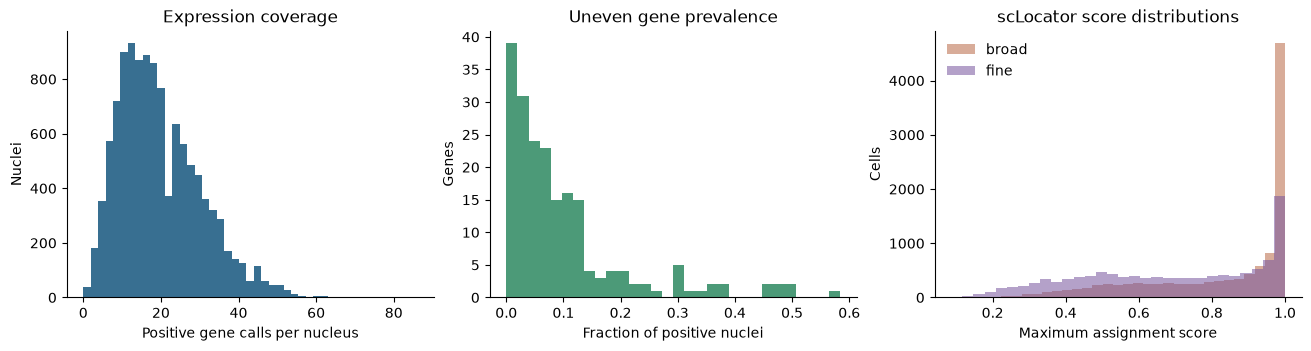

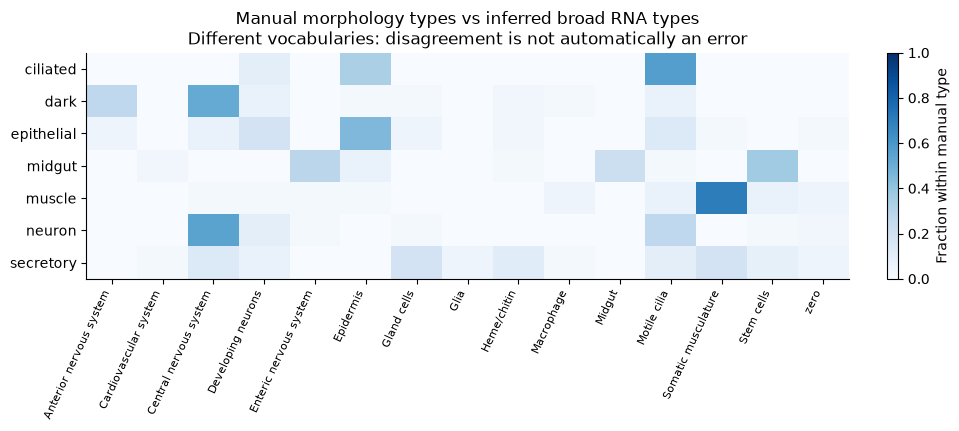

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), layout='constrained')
axes[0].hist(expression_nuclei.sum(axis=1), bins=45, color='#386f91')
axes[0].set(xlabel='Positive gene calls per nucleus', ylabel='Nuclei', title='Expression coverage')
axes[1].hist(gene_qc.prevalence, bins=30, color='#4c9a78')
axes[1].set(xlabel='Fraction of positive nuclei', ylabel='Genes', title='Uneven gene prevalence')
for name, color in [('broad', '#b86845'), ('fine', '#77559d')]:
    axes[2].hist(annotation_qc[name + '_max_score'], bins=30, alpha=.55, label=name, color=color)
axes[2].set(xlabel='Maximum assignment score', ylabel='Cells', title='scLocator score distributions')
axes[2].legend(frameon=False)
save_figure(fig, 'data_and_annotation_qc')

fig, ax = plt.subplots(figsize=(9.5, 4.2), layout='constrained')
tab = pd.crosstab(annotation_qc.manual_type, annotation_qc.broad_type)
image = ax.imshow(tab.div(tab.sum(axis=1), axis=0), vmin=0, vmax=1, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(tab.columns)), tab.columns, rotation=65, ha='right', fontsize=8)
ax.set_yticks(range(len(tab)), tab.index)
ax.set_title('Manual morphology types vs inferred broad RNA types\nDifferent vocabularies: disagreement is not automatically an error')
fig.colorbar(image, ax=ax, label='Fraction within manual type')
save_table(tab.reset_index(), 'manual_vs_sclocator_counts')
save_figure(fig, 'manual_vs_sclocator')

## 3. A transparent joint vector, with controlled block influence

Use the following baselines on **identical cells**: DINO alone; original MorphoFeatures alone; expression alone; and each morphology block combined with expression. A raw concatenation lets variance and dimension determine the weight of each modality. A global z-score, conversely, can give a rare/noisy binary gene disproportionate influence.

The default below centers each feature, removes training-constant columns and normalizes each modality's row to unit L2 length. It then concatenates `sqrt(1-w) × morphology` and `sqrt(w) × expression`. Before optional PCA, squared Euclidean distance is the weighted sum of the two block distances. `w=0.5` gives equal block influence, **not** equal biological reliability. All feature dimensions within each retained block are preserved in the exported joint vectors. The mean-centering step means absence as well as presence contributes to expression similarity.

Keep binary calls binary before this transformation: no counts-per-cell normalization or `log1p` is needed. For expression-only neighborhood sensitivity checks, Jaccard distance emphasizes shared positive calls, while Hamming includes shared absences. Alternative gene z-scoring is exposed above but should be treated as a distinct experiment, especially for rare genes.

For pictures, fitting preprocessing on all selected cells is an unsupervised/transductive exploration. For classifier and gene-prediction scores, **all fitted preprocessing is learned from training folds only**. Never classify using a PCA/UMAP fitted on the entire test-inclusive data and call that an inductive validation. Do not concatenate UMAP coordinates as though they were the original feature blocks.

In [14]:
class BalancedBlocks(BaseEstimator, TransformerMixin):
    def __init__(self, block_sizes, weights, standardize=False):
        self.block_sizes = block_sizes
        self.weights = weights
        self.standardize = standardize

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=np.float64)
        assert sum(self.block_sizes) == X.shape[1] and np.isfinite(X).all()
        assert len(self.weights) == len(self.block_sizes) and np.isclose(sum(self.weights), 1)
        assert min(self.weights) > 0
        self.blocks_ = []
        start = 0
        for width in self.block_sizes:
            block = X[:, start:start + width]
            keep = np.ptp(block, axis=0) > 0
            if not keep.any():
                raise ValueError('A training modality has no variable features; inspect the cohort/folds.')
            mean = block[:, keep].mean(axis=0)
            scale = block[:, keep].std(axis=0) if self.standardize else np.ones(keep.sum())
            self.blocks_.append((start, width, keep, mean, scale))
            start += width
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        output = []
        for weight, (start, width, keep, mean, scale) in zip(self.weights, self.blocks_):
            block = (X[:, start:start + width][:, keep] - mean) / scale
            output.append(np.sqrt(weight) * normalize(block))
        return np.concatenate(output, axis=1)

representations = {
    'DINO': {'X': D, 'sizes': (D.shape[1],), 'weights': (1.0,)},
    'MorphoFeatures': {'X': M, 'sizes': (M.shape[1],), 'weights': (1.0,)},
    'Expression': {'X': E, 'sizes': (E.shape[1],), 'weights': (1.0,)},
}
for w in EXPRESSION_WEIGHTS:
    assert 0 < w < 1, 'Fusion weights must be strictly between 0 and 1; use the separate baselines at the endpoints.'
    representations[f'DINO + expression ({w:.2f})'] = {
        'X': np.column_stack([D, E]), 'sizes': (D.shape[1], E.shape[1]), 'weights': (1-w, w)}
representations['MorphoFeatures + expression (0.50)'] = {
    'X': np.column_stack([M, E]), 'sizes': (M.shape[1], E.shape[1]), 'weights': (.5, .5)}
PRIMARY_DINO_JOINT = f'DINO + expression ({min(EXPRESSION_WEIGHTS, key=lambda w: abs(w-.5)):.2f})'

def slug(name):
    return re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')

transformed, pca_spaces, pca_variance = {}, {}, []
for name, recipe in representations.items():
    transform = BalancedBlocks(recipe['sizes'], recipe['weights'], STANDARDIZE_EACH_FEATURE)
    Z = transform.fit_transform(recipe['X'])
    transformed[name] = Z
    pca = PCA(n_components=min(200, *Z.shape), svd_solver='randomized', random_state=SEED)
    pca_spaces[name] = pca.fit_transform(Z)
    pca_variance.append({'representation': name, 'dimensions': Z.shape[1],
        'pca_dimensions': pca.n_components_, 'retained_variance': pca.explained_variance_ratio_.sum()})
    native_ids = mapping.loc[ids, 'nucleus_id'].to_numpy(dtype=np.int64)
    np.savez_compressed(OUT / 'vectors' / f'{slug(name)}.npz', label_ids=ids.to_numpy(dtype=np.int64),
                        nucleus_ids=native_ids, features=Z.astype(np.float32))
    blocks = []
    arrays = {}
    boundary = 0
    for i, (weight, (start, width, keep, mean, scale)) in enumerate(zip(recipe['weights'], transform.blocks_)):
        arrays.update({f'block_{i}_keep': keep, f'block_{i}_mean': mean, f'block_{i}_scale': scale})
        blocks.append({'input_start': start, 'input_width': width, 'output_start': boundary,
                       'output_stop': boundary + int(keep.sum()), 'weight': weight})
        boundary += int(keep.sum())
    np.savez_compressed(OUT / 'models' / f'{slug(name)}_exploratory_transform.npz',
                        **arrays, pca_components=pca.components_, pca_mean=pca.mean_)
    source_paths = ([str(expression_files[0])] if name == 'Expression' else
                    [str(DINO_PATH if name.startswith('DINO') else MORPHO_PATH)])
    if '+' in name:
        source_paths.append(str(expression_files[0]))
    write_json({'name': name, 'id_namespace': 'cell', 'nucleus_id_lookup': '../tables/cohort_audit.tsv',
                'fit_scope': 'all analysis cells; descriptive, not a validation fit',
                'preprocessing': 'training-feature centering, optional z-score, row L2 per block, sqrt-weight concatenation',
                'feature_standardization': STANDARDIZE_EACH_FEATURE, 'blocks': blocks,
                'expression_columns': expression_nuclei.columns.tolist(),
                'sources': source_paths},
               OUT / 'vectors' / f'{slug(name)}.metadata.json')
save_table(pd.DataFrame(pca_variance), 'exploratory_pca_variance')
display(pd.DataFrame(pca_variance).round(3))

,representation,dimensions,pca_dimensions,retained_variance
0,DINO,768,200,0.997
1,MorphoFeatures,480,200,0.980
2,Expression,200,200,1.000
3,DINO + expression (0.25),968,200,0.985
4,DINO + expression (0.50),968,200,0.985
5,DINO + expression (0.75),968,200,0.990
6,MorphoFeatures + expression (0.50),680,200,0.904


## 4. Compare clustering and pictures without moving the goalposts

K-means below uses the selected **PCA feature space**, not the two plotted UMAP coordinates. The same cohort, PCA dimension, cluster-count choices and seeds are used across representations. UMAP is a display: visually tighter islands are not a validation score. Each representation fits a separate space, so its plot axes are not shared coordinates.

The PCA variance table matters: a fixed number of PCs can retain very different fractions of each representation. In this dataset, 50 PCs retain about 99% of DINO variance but only 59% of the balanced original-MorphoFeatures/expression fusion. Check other dimensions and `CLASSIFIER_USE_PCA=False` before attributing a difference exclusively to biological complementarity. The exported joint vectors retain every nonconstant dimension before PCA.

We report adjusted Rand index (ARI) and adjusted mutual information (AMI) against the available manual labels on the labeled subset. AMI here describes **two discrete partitions**; it is not the mutual information between complete embedding and expression vectors. Agreement with scLocator is included only as a descriptive comparison and is circular evidence for expression-containing vectors. The manual classes (`dark`, `neuron`, etc.) and scLocator's RNA categories describe different levels of biology.

,representation,clusters,manual_ARI,manual_AMI,sclocator_AMI_descriptive_only
0,DINO,8,0.400,0.498,0.118
1,DINO,15,0.404,0.532,0.129
2,MorphoFeatures,8,0.436,0.653,0.177
3,MorphoFeatures,15,0.433,0.619,0.164
4,Expression,8,0.380,0.457,0.403
5,Expression,15,0.397,0.477,0.408
6,DINO + expression (0.25),8,0.459,0.565,0.157
7,DINO + expression (0.25),15,0.407,0.542,0.168
8,DINO + expression (0.50),8,0.463,0.581,0.242
9,DINO + expression (0.50),15,0.498,0.600,0.268


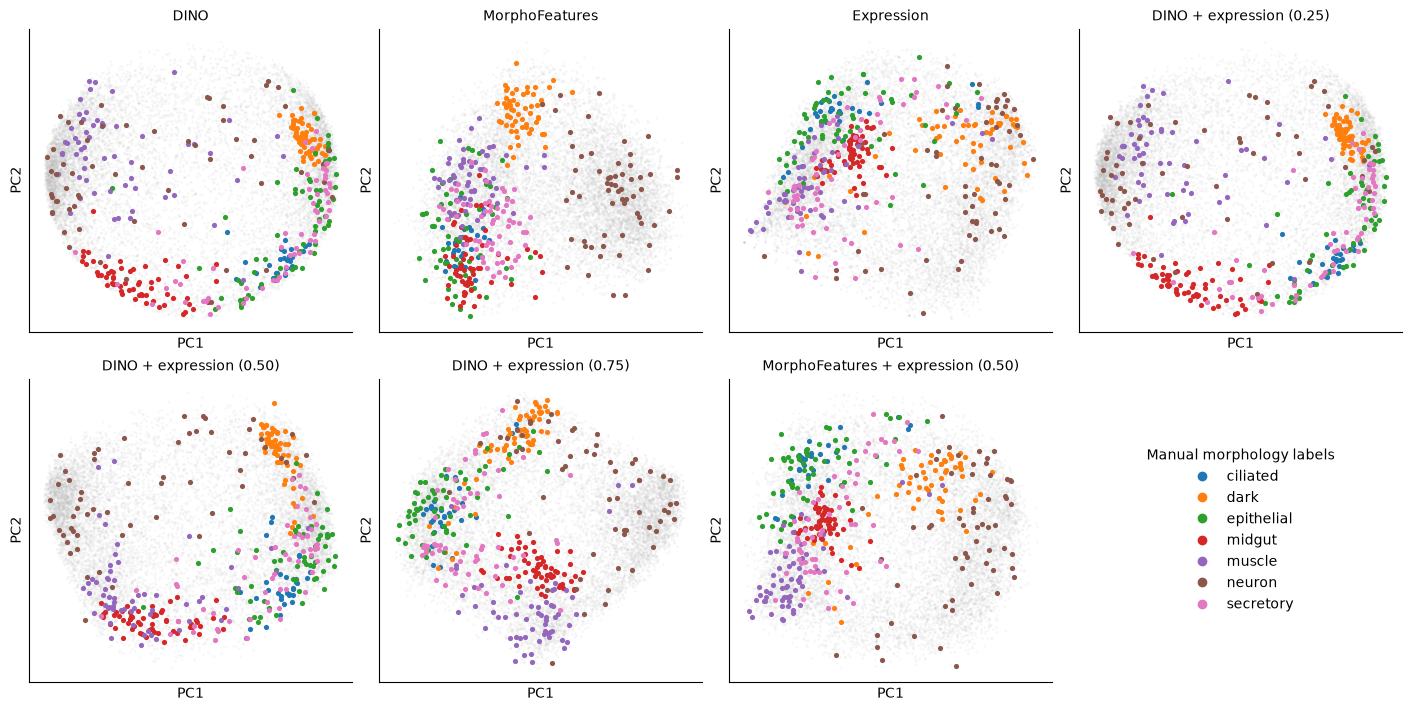

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fitting UMAP: DINO


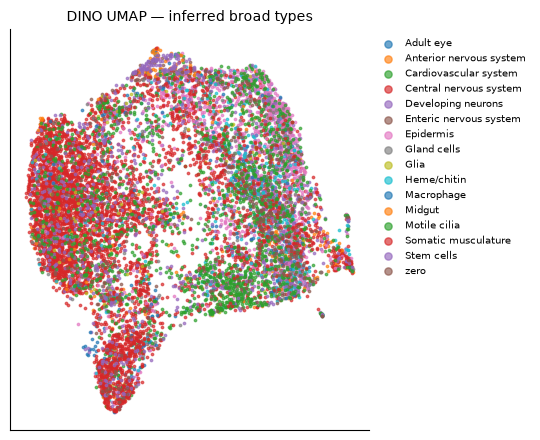

Fitting UMAP: MorphoFeatures


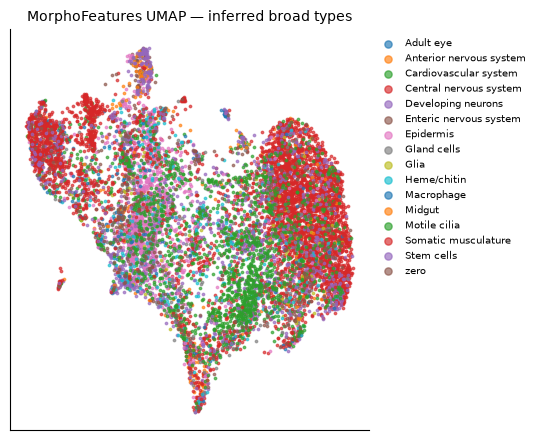

Fitting UMAP: Expression
Fitting UMAP: DINO + expression (0.50)
Fitting UMAP: MorphoFeatures + expression (0.50)


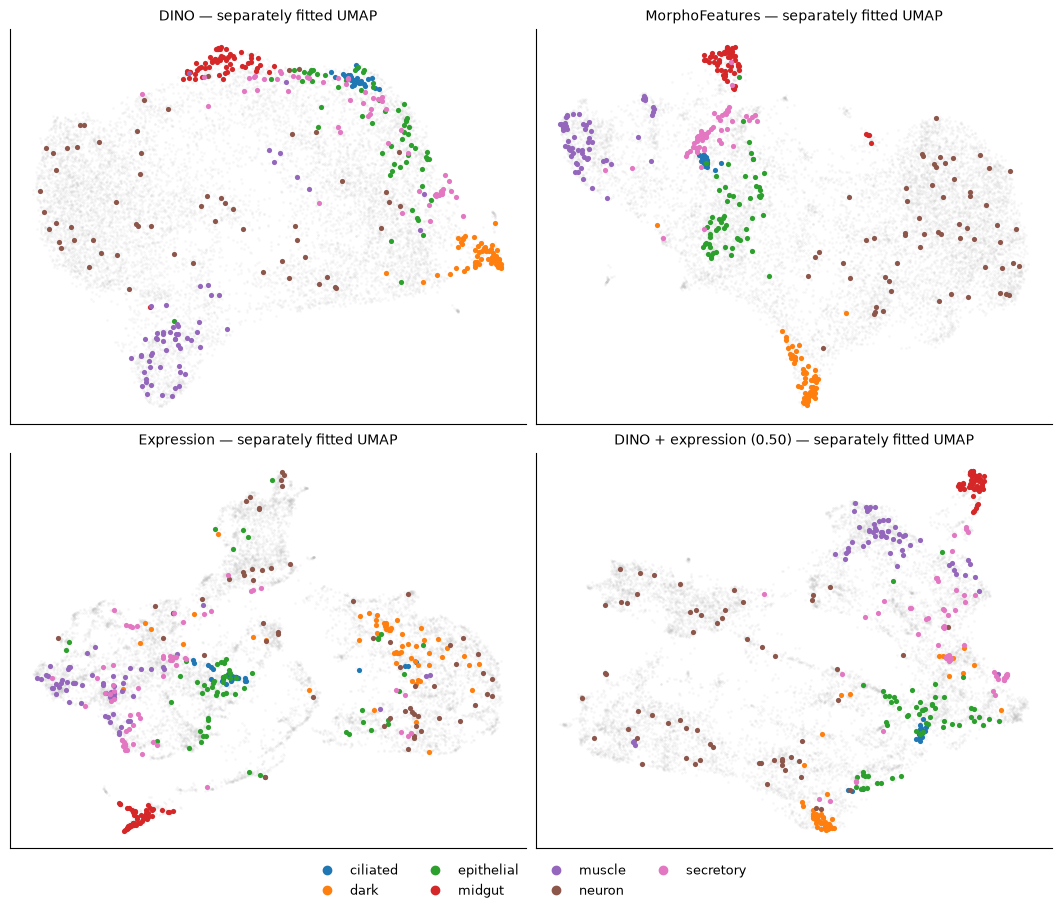

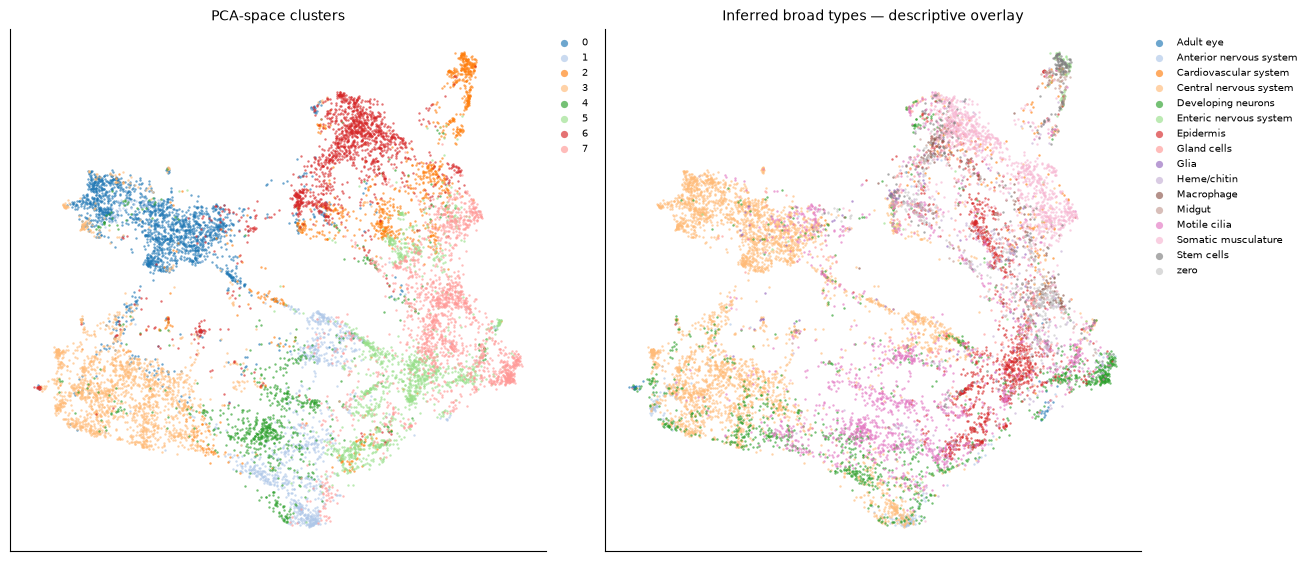

In [15]:
cluster_results, cluster_labels = [], {}
annotated = labels.notna().to_numpy()
truth = labels.loc[labels.notna()].astype(str).to_numpy()
for name, Z in pca_spaces.items():
    for k in CLUSTER_COUNTS:
        clusters = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z)
        cluster_labels[name, k] = clusters
        cluster_results.append({'representation': name, 'clusters': k,
            'manual_ARI': adjusted_rand_score(truth, clusters[annotated]),
            'manual_AMI': adjusted_mutual_info_score(truth, clusters[annotated]),
            'sclocator_AMI_descriptive_only': adjusted_mutual_info_score(annotation_qc.broad_type, clusters)})
cluster_scores = pd.DataFrame(cluster_results)
save_table(cluster_scores, 'clustering_comparisons')
display(cluster_scores.round(3))

manual_order = sorted(manual.unique())
manual_colors = dict(zip(manual_order, plt.get_cmap('tab10').colors))
def draw_manual(ax, coordinates, title):
    ax.scatter(coordinates[~annotated, 0], coordinates[~annotated, 1], s=3, c='#b6b6b6', alpha=.12,
               rasterized=True, linewidths=0)
    for label in manual_order:
        take = labels.eq(label).to_numpy()
        ax.scatter(coordinates[take, 0], coordinates[take, 1], s=14, color=manual_colors[label],
                   linewidths=0, rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained')
for ax, (name, Z) in zip(axes.flat, pca_spaces.items()):
    draw_manual(ax, Z[:, :2], name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
for ax in list(axes.flat)[len(pca_spaces):]:
    ax.set_axis_off()
handles = [Line2D([], [], marker='o', linestyle='', color=manual_colors[v], label=v) for v in manual_order]
axes.flat[-1].legend(handles=handles, loc='center', frameon=False, title='Manual morphology labels')
save_figure(fig, 'pca_representation_comparison')

umap_spaces = {}
plot_names = ['DINO', 'MorphoFeatures', 'Expression', PRIMARY_DINO_JOINT, 'MorphoFeatures + expression (0.50)']
if RUN_UMAP:
    from umap import UMAP
    for name in plot_names:
        print('Fitting UMAP:', name, flush=True)
        Z = pca_spaces[name]
        xy = UMAP(n_components=2, n_neighbors=UMAP_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                  random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(Z)
        umap_spaces[name] = xy
        coordinates = pd.DataFrame({'cell_id': ids, 'nucleus_id': mapping.loc[ids, 'nucleus_id'],
            'umap_1': xy[:, 0], 'umap_2': xy[:, 1], 'manual_type': labels,
            'sclocator_broad_type': annotation_qc.broad_type,
            'embedding_cluster': cluster_labels[name, CLUSTER_COUNTS[0]]})
        save_table(coordinates, slug(name) + '_umap')
        
        # also plot the DINO and MorphoFeatures only UMAP coordinates inferred broad types mapped on 
        if name in ['DINO', 'MorphoFeatures']:
            fig, ax = plt.subplots(figsize=(5.5, 4.5), layout='tight')
            for broad_type in sorted(annotation_qc.broad_type.unique()):
                take = annotation_qc.broad_type.eq(broad_type).to_numpy()
                ax.scatter(xy[take, 0], xy[take, 1], s=3, alpha=.65, label=broad_type)
            ax.set_title(f'{name} UMAP — inferred broad types', fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
            ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=7, markerscale=3)
            save_figure(fig, slug(name) + '_umap_broad_types')
            
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 9), layout='constrained')
    for ax, (name, xy) in zip(axes.flat, umap_spaces.items()):
        draw_manual(ax, xy, name + ' — separately fitted UMAP')
    fig.legend(handles=handles, loc='outside lower center', ncols=4, frameon=False, fontsize=9)
    save_figure(fig, 'umap_representation_comparison')
    

    # Same joint map: clusters beside inferred broad labels, each with its own legend.
    name = PRIMARY_DINO_JOINT
    xy = umap_spaces[name]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
    for ax, categories, title in [
        (axes[0], pd.Series(cluster_labels[name, CLUSTER_COUNTS[0]], index=ids).astype(str), 'PCA-space clusters'),
        (axes[1], annotation_qc.broad_type, 'Inferred broad types — descriptive overlay')]:
        levels = sorted(categories.unique())
        palette = plt.get_cmap('tab20').colors
        for j, category in enumerate(levels):
            take = categories.eq(category).to_numpy()
            ax.scatter(xy[take, 0], xy[take, 1], s=3, alpha=.65, color=palette[j % 20],
                       linewidths=0, rasterized=True, label=category)
        ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=7, markerscale=3)
    save_figure(fig, 'joint_map_clusters_and_sclocator')
    
    
    

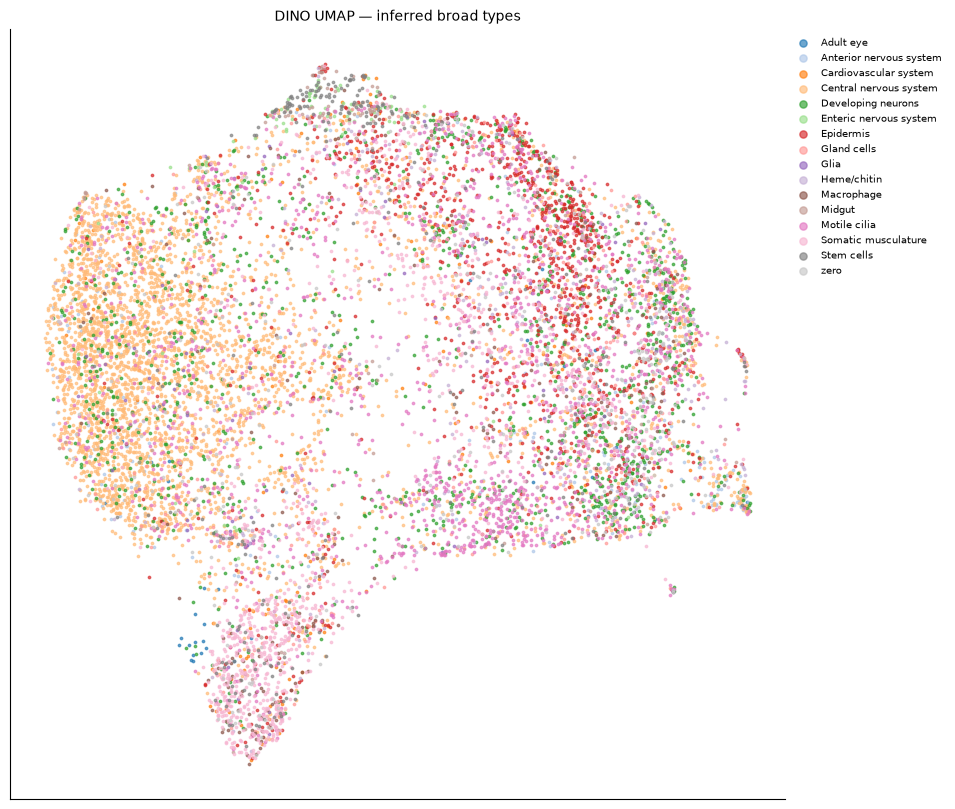

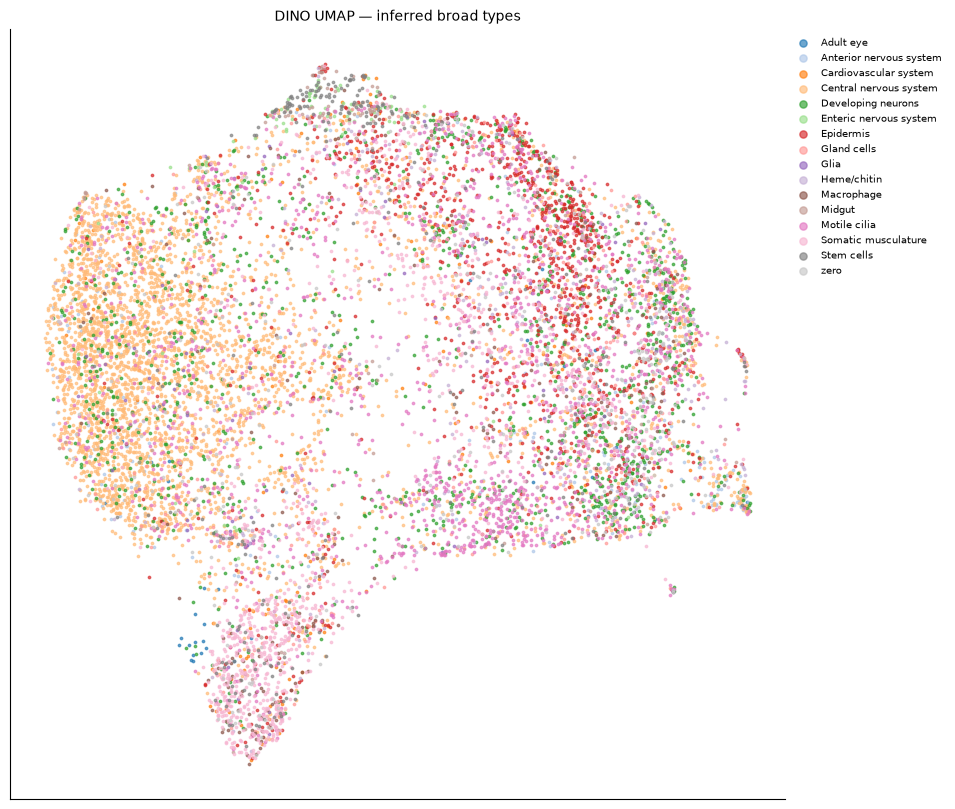

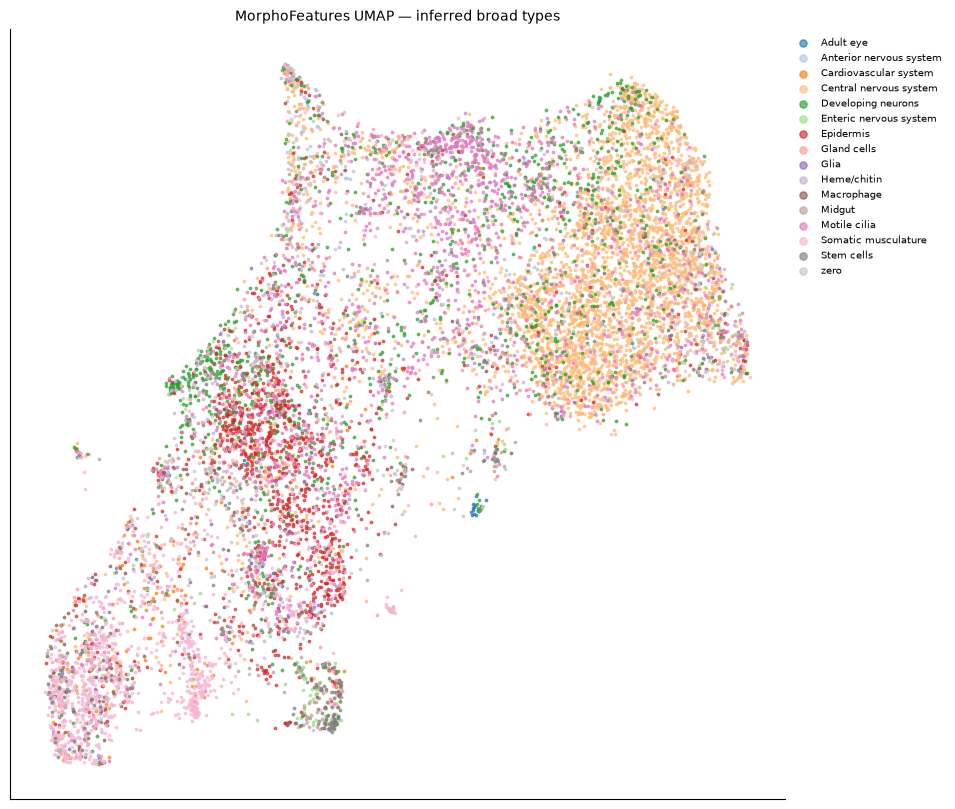

Validated 11,377 ordered cell IDs; broad probability winners and nucleus mappings agree; 16 broad labels have distinct colors.


In [ ]:
broad_labels = annotation_qc['broad_type'].reindex(ids)
broad_winners = probability_tables['broad'].idxmax(axis=1).reindex(ids)
assert broad_labels.index.equals(broad_winners.index)


In [ ]:
transformed

{'DINO': array([[-0.00640774, -0.01164145,  0.01587383, ..., -0.03710592,
          0.01712265,  0.03323644],
        [ 0.01359617, -0.05849098, -0.00387252, ..., -0.01512837,
          0.00217961,  0.06952471],
        [-0.00795173,  0.00245878,  0.02259265, ..., -0.00664864,
          0.00609408, -0.00500477],
        ...,
        [ 0.00710333, -0.02434576, -0.03123245, ..., -0.00043385,
          0.02034048, -0.00967666],
        [ 0.00736215,  0.02796816, -0.01931257, ..., -0.02855415,
          0.01879554, -0.05971177],
        [ 0.01436615,  0.06489209,  0.05456874, ..., -0.00257514,
         -0.01950579, -0.02150718]], shape=(11377, 768)),
 'MorphoFeatures': array([[ 0.07327871,  0.05613825,  0.00293804, ..., -0.01165574,
          0.02242137,  0.039067  ],
        [ 0.09871255, -0.03471597,  0.02011894, ..., -0.03661133,
          0.00670956,  0.02321921],
        [ 0.04154154, -0.02007737,  0.00786693, ..., -0.04576689,
         -0.05804676,  0.06412548],
        ...,
        

Fitting raw StandardScaler + UMAP: DINO


Fitting raw StandardScaler + UMAP: DINO


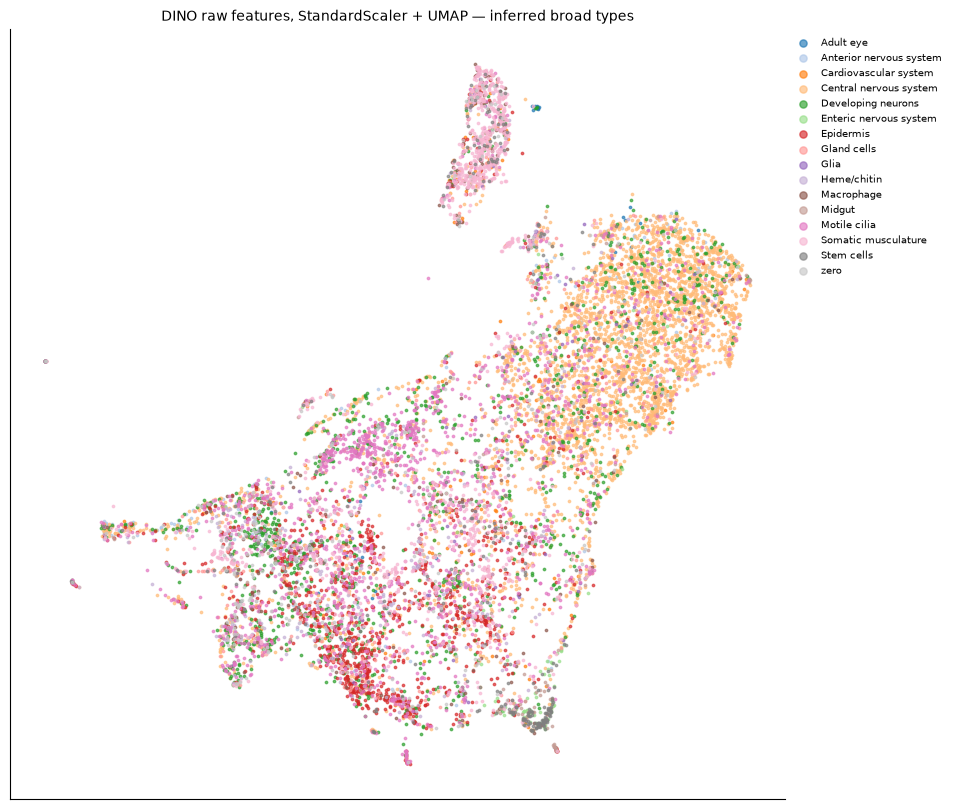

Fitting raw StandardScaler + UMAP: MorphoFeatures


Fitting raw StandardScaler + UMAP: DINO


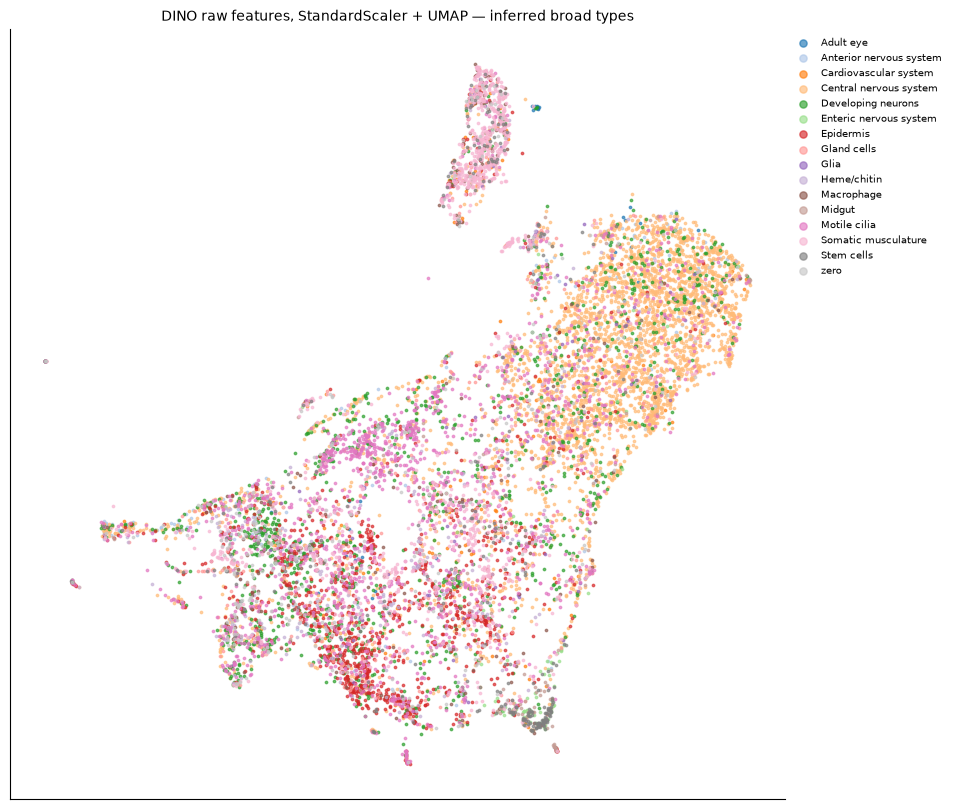

Fitting raw StandardScaler + UMAP: MorphoFeatures


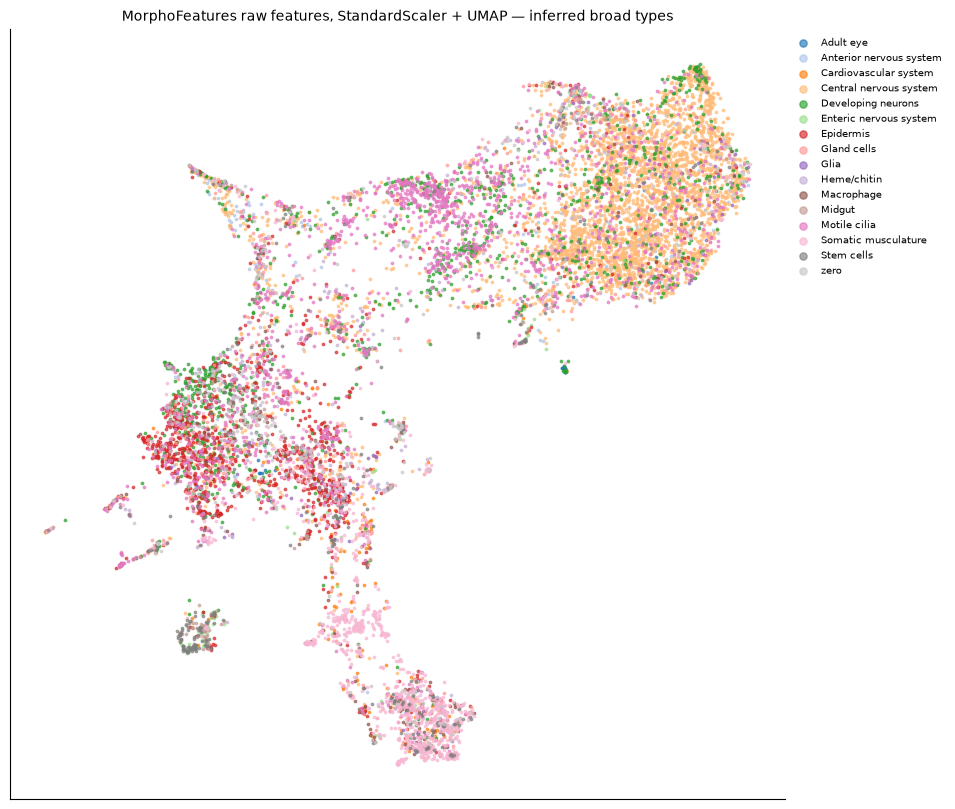

Completed raw-feature StandardScaler + UMAP for 2 representations.


In [ ]:
raw_feature_sets = {'DINO': D, 'MorphoFeatures': M}
raw_standardized_umap_spaces = {}
assert broad_labels.index.equals(ids)
for name, raw_features in raw_feature_sets.items():
    print('Fitting raw StandardScaler + UMAP:', name, flush=True)
    assert raw_features.shape[0] == len(ids) and np.isfinite(raw_features).all()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(raw_features)
    assert np.isfinite(X_scaled).all()
    xy_scaled = UMAP(n_components=2, n_neighbors=15, min_dist=0,
                     random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(X_scaled)
    raw_standardized_umap_spaces[name] = xy_scaled
    coordinates = pd.DataFrame({
        'cell_id': ids,
        'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
        'umap_1': xy_scaled[:, 0],
        'umap_2': xy_scaled[:, 1],
        'manual_type': labels.to_numpy(),
        'sclocator_broad_type': broad_labels.to_numpy(),
    })
    save_table(coordinates, slug(name) + '_raw_standard_scaled_umap')

    fig, ax = plt.subplots(figsize=(10, 10))
    for broad_type in broad_levels:
        take = broad_labels.eq(broad_type).to_numpy()
        ax.scatter(xy_scaled[take, 0], xy_scaled[take, 1], s=3, alpha=.65,
                   color=broad_type_colors[broad_type], label=broad_type)
    ax.set_title(f'{name} raw features, StandardScaler + UMAP — inferred broad types', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=7, markerscale=3)
    save_figure(fig, slug(name) + '_raw_standard_scaled_umap_broad_types')

print(f'Completed raw-feature StandardScaler + UMAP for {len(raw_standardized_umap_spaces)} representations.')

Fitting raw StandardScaler + UMAP: DINO


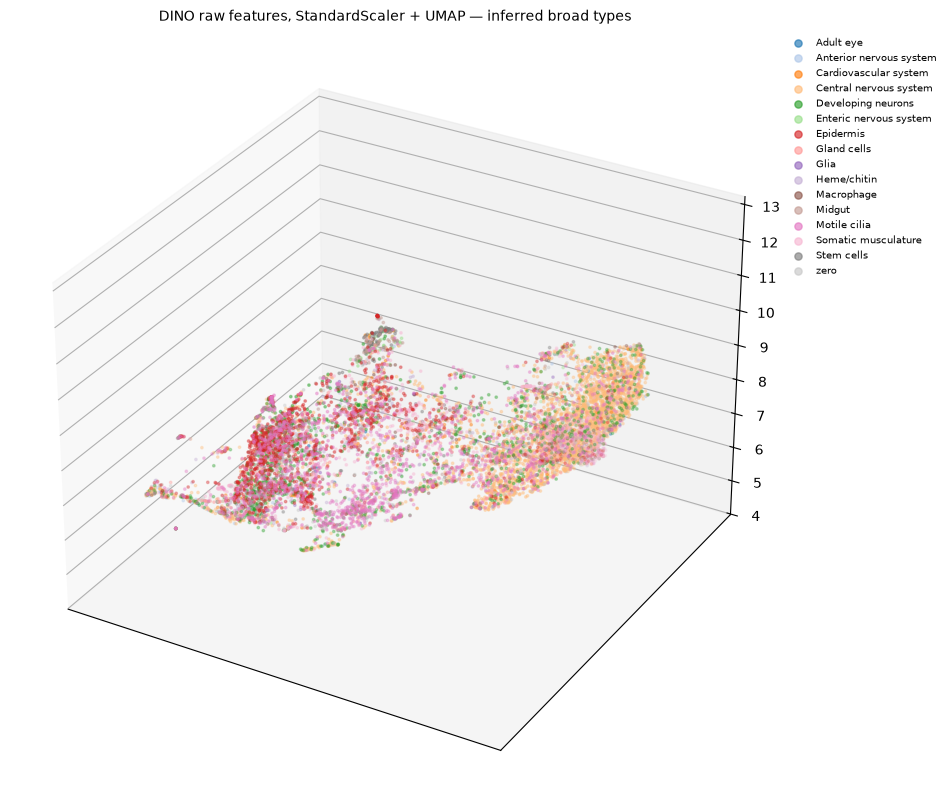

Fitting raw StandardScaler + UMAP: MorphoFeatures


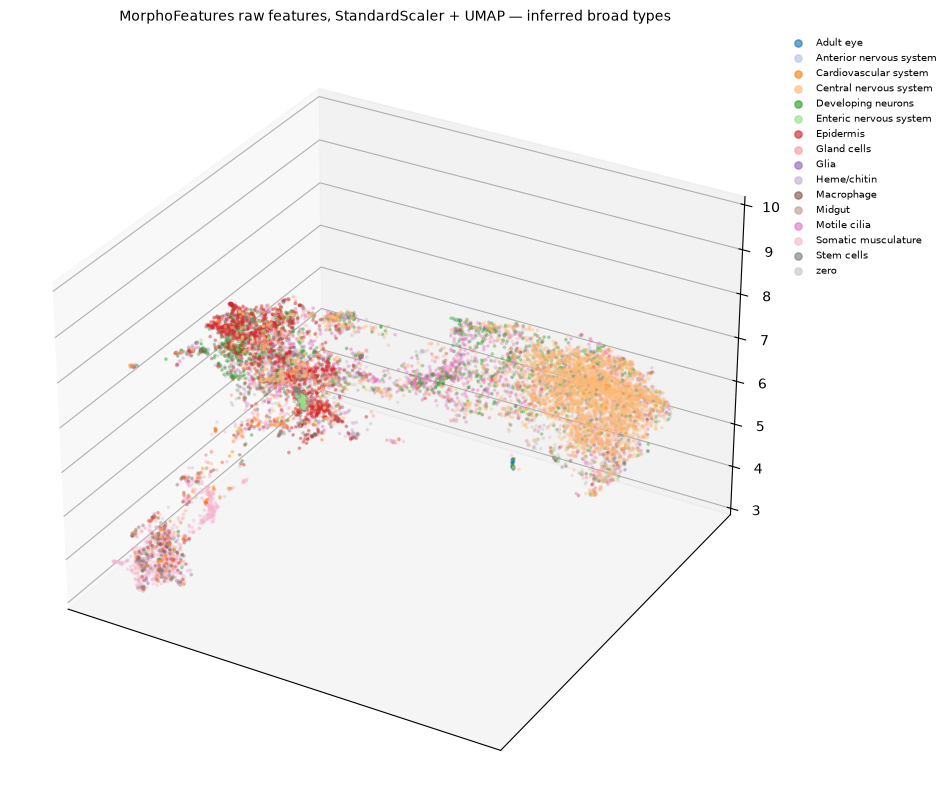

Fitting raw StandardScaler + UMAP: Expression


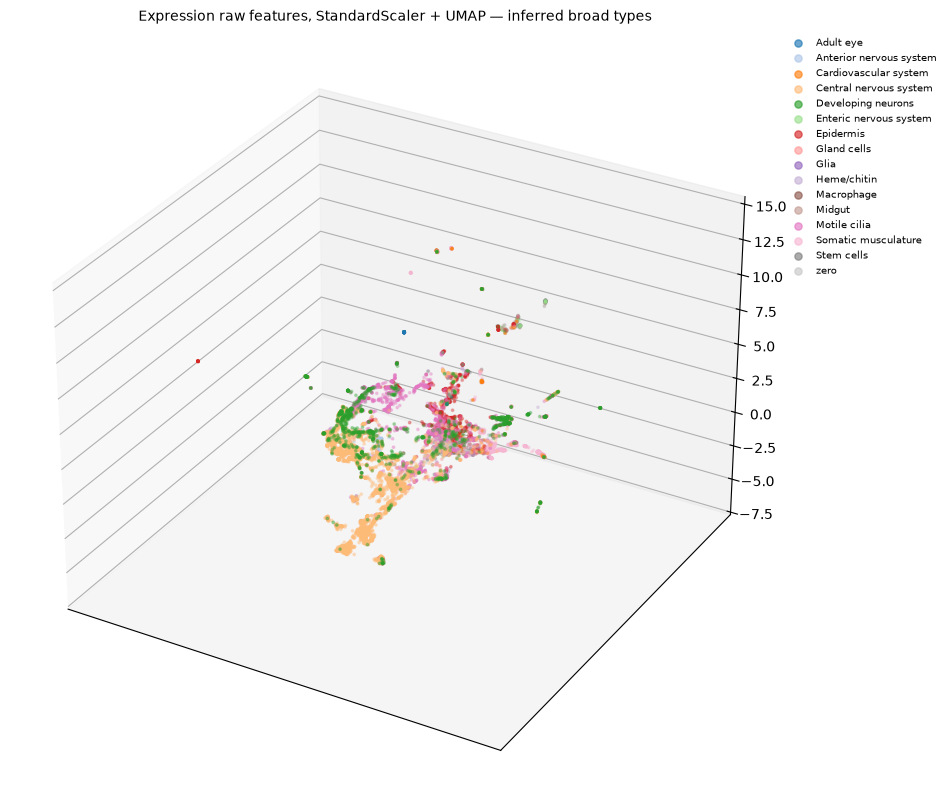

Completed raw-feature StandardScaler + UMAP for 3 representations.


In [ ]:
from umap import UMAP
raw_feature_sets = {'DINO': D, 'MorphoFeatures': M, 'Expression': E}
raw_standardized_umap_spaces = {}
assert broad_labels.index.equals(ids)
for name, raw_features in raw_feature_sets.items():
    print('Fitting raw StandardScaler + UMAP:', name, flush=True)
    assert raw_features.shape[0] == len(ids) and np.isfinite(raw_features).all()
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(raw_features)
    assert np.isfinite(X_scaled).all()
    xy_scaled = UMAP(n_components=3, n_neighbors=15, min_dist=0,
                     random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(X_scaled)
    raw_standardized_umap_spaces[name] = xy_scaled
    coordinates = pd.DataFrame({
        'cell_id': ids,
        'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
        'umap_1': xy_scaled[:, 0],
        'umap_2': xy_scaled[:, 1],
        'umap_3': xy_scaled[:, 2],
        'manual_type': labels.to_numpy(),
        'sclocator_broad_type': broad_labels.to_numpy(),
    })
    save_table(coordinates, slug(name) + '_raw_standard_scaled_umap')

    # plot in 3D with inferred broad types
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': '3d'})
    for broad_type in broad_levels:
        take = broad_labels.eq(broad_type).to_numpy()
        ax.scatter(xy_scaled[take, 0], xy_scaled[take, 1], xy_scaled[take, 2], s=3, alpha=.65,
                   color=broad_type_colors[broad_type], label=broad_type)
    ax.set_title(f'{name} raw features, StandardScaler + UMAP — inferred broad types', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=7, markerscale=3)
    save_figure(fig, slug(name) + '_raw_standard_scaled_umap_broad_types')

print(f'Completed raw-feature StandardScaler + UMAP for {len(raw_standardized_umap_spaces)} representations.')

In [ ]:
raw_standardized_umap_spaces

{'DINO': array([[ 6.3637238 , -0.1806949 ,  9.160645  ],
        [ 5.9532795 , -0.45225486,  9.371769  ],
        [ 6.6398983 , -0.69611084,  8.0502405 ],
        ...,
        [ 4.9635196 , -1.1909312 ,  8.1813135 ],
        [ 4.644978  , -0.3156834 ,  7.300354  ],
        [ 8.270691  ,  1.5238612 ,  9.771813  ]],
       shape=(11377, 3), dtype=float32),
 'MorphoFeatures': array([[ 7.7602444,  2.0592754,  7.8599043],
        [ 7.7102847,  4.2570944,  8.132949 ],
        [ 7.2644243,  2.6021514,  7.1679482],
        ...,
        [ 6.798216 ,  3.6123374,  7.131671 ],
        [ 6.5321984,  2.324949 ,  7.339802 ],
        [10.500885 ,  5.9039474,  6.13984  ]],
       shape=(11377, 3), dtype=float32),
 'Expression': array([[6.067226 , 2.9431136, 6.4244986],
        [5.929155 , 3.0766635, 6.4057107],
        [5.618204 , 1.5308483, 5.2967796],
        ...,
        [8.371673 , 3.7087631, 6.5578237],
        [9.773291 , 3.8209753, 4.2915516],
        [8.789817 , 3.7439892, 2.5908003]], shape=(1

In [ ]:
# project in 3D with Plotly for interactive visualization
import plotly.express as px
import plotly
for name, xy_scaled in raw_standardized_umap_spaces.items():
    coordinates = pd.DataFrame({
        'cell_id': ids,
        'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
        'umap_1': xy_scaled[:, 0],
        'umap_2': xy_scaled[:, 1],
        'umap_3': xy_scaled[:, 2],
        'manual_type': labels.to_numpy(),
        'sclocator_broad_type': broad_labels.to_numpy(),
    })
    fig = px.scatter_3d(coordinates, x='umap_1', y='umap_2', z='umap_3',
                        color='sclocator_broad_type', color_discrete_sequence=px.colors.qualitative.Dark24, hover_data=['cell_id', 'nucleus_id', 'manual_type'],
                        title=f'{name} raw features, StandardScaler + UMAP — inferred broad types')
    fig.update_traces(marker=dict(size=3, opacity=0.65))
    # increase size of the legend markers for better visibility
    fig.update_layout(legend=dict(itemsizing='constant', title='Inferred broad types',
                                  font=dict(size=10), traceorder='normal'))
    fig.write_html(OUT / f'{slug(name)}_raw_standard_scaled_umap_broad_types.html')
    # open in IDE preview
    #fig.show()

In [ ]:
# project the expression data with broad types in 3D with Plotly for interactive visualization
xy_scaled = raw_standardized_umap_spaces['Expression']
coordinates = pd.DataFrame({
    'cell_id': ids,
    'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
    'umap_1': xy_scaled[:, 0],
    'umap_2': xy_scaled[:, 1],
    'umap_3': xy_scaled[:, 2],
    'manual_type': labels.to_numpy(),
    'sclocator_broad_type': broad_labels.to_numpy(),
})
fig = px.scatter_3d(coordinates, x='umap_1', y='umap_2', z='umap_3',
                    color='sclocator_broad_type', color_discrete_sequence=px.colors.qualitative.Dark24, hover_data=['cell_id', 'nucleus_id', 'manual_type'],
                    title='Expression raw features, StandardScaler + UMAP — inferred broad types')
fig.update_traces(marker=dict(size=3, opacity=0.65))
# increase size of the legend markers for better visibility
fig.update_layout(legend=dict(itemsizing='constant', title='Inferred broad types',
                              font=dict(size=10), traceorder='normal'))
fig.write_html(OUT / 'expression_raw_standard_scaled_umap_broad_types.html')

In [ ]:
plot_names = ['DINO', 'MorphoFeatures']

In [ ]:
# take the PCA of each representation and then concatenate the PCA components for a joint UMAP
pca_joint_features = np.column_stack([pca_spaces[name] for name in plot_names])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_joint_features)
xy_scaled = UMAP(n_components=3, n_neighbors=15, min_dist=0,
                 random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(X_scaled)
coordinates = pd.DataFrame({
    'cell_id': ids,
    'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
    'umap_1': xy_scaled[:, 0],
    'umap_2': xy_scaled[:, 1],
    'umap_3': xy_scaled[:, 2],
    'manual_type': labels.to_numpy(),
    'sclocator_broad_type': broad_labels.to_numpy(),
})
save_table(coordinates, 'joint_pca_umap')
fig = px.scatter_3d(coordinates, x='umap_1', y='umap_2', z='umap_3',
                    color='sclocator_broad_type', color_discrete_sequence=px.colors.qualitative.Dark24, hover_data=['cell_id', 'nucleus_id', 'manual_type'],
                    title='Joint PCA features, StandardScaler + UMAP — inferred broad types')
fig.update_traces(marker=dict(size=3, opacity=0.65))
# increase size of the legend markers for better visibility
fig.update_layout(legend=dict(itemsizing='constant', title='Inferred broad types',
                              font=dict(size=10), traceorder='normal'))
fig.write_html(OUT / 'joint_morpho_dino_pca_scaled_umap_broad_types.html')

In [ ]:
# take the PCA of each representation and then concatenate the PCA components for a joint UMAP
raw_joint_features = np.column_stack([raw_feature_sets[name] for name in plot_names])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(raw_joint_features)
xy_scaled = UMAP(n_components=3, n_neighbors=15, min_dist=0,
                 random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(X_scaled)
coordinates = pd.DataFrame({
    'cell_id': ids,
    'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
    'umap_1': xy_scaled[:, 0],
    'umap_2': xy_scaled[:, 1],
    'umap_3': xy_scaled[:, 2],
    'manual_type': labels.to_numpy(),
    'sclocator_broad_type': broad_labels.to_numpy(),
})
save_table(coordinates, 'joint_pca_umap')
fig = px.scatter_3d(coordinates, x='umap_1', y='umap_2', z='umap_3',
                    color='sclocator_broad_type', color_discrete_sequence=px.colors.qualitative.Dark24, hover_data=['cell_id', 'nucleus_id', 'manual_type'],
                    title='Joint Raw features, StandardScaler + UMAP — inferred broad types')
fig.update_traces(marker=dict(size=3, opacity=0.65))
# increase size of the legend markers for better visibility
fig.update_layout(legend=dict(itemsizing='constant', title='Inferred broad types',
                              font=dict(size=10), traceorder='normal'))
fig.write_html(OUT / 'joint_morpho_dino_raw_scaled_umap_broad_types.html')

In [ ]:
# take the PCA of each representation and then concatenate the PCA components for a joint UMAP
raw_joint_features = np.column_stack([raw_feature_sets[name] for name in plot_names])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(raw_joint_features)
pca = PCA(n_components=150)
joint_pca_features = pca.fit_transform(X_scaled)
xy_scaled = UMAP(n_components=3, n_neighbors=15, min_dist=0,
                 random_state=SEED, n_jobs=1, metric='euclidean').fit_transform(joint_pca_features)
coordinates = pd.DataFrame({
    'cell_id': ids,
    'nucleus_id': mapping.loc[ids, 'nucleus_id'].to_numpy(),
    'umap_1': xy_scaled[:, 0],
    'umap_2': xy_scaled[:, 1],
    'umap_3': xy_scaled[:, 2],
    'manual_type': labels.to_numpy(),
    'sclocator_broad_type': broad_labels.to_numpy(),
})
save_table(coordinates, 'joint_pca_umap')
fig = px.scatter_3d(coordinates, x='umap_1', y='umap_2', z='umap_3',
                    color='sclocator_broad_type', color_discrete_sequence=px.colors.qualitative.Dark24, hover_data=['cell_id', 'nucleus_id', 'manual_type'],
                    title='Joint Raw features then PCA, StandardScaler + UMAP — inferred broad types')
fig.update_traces(marker=dict(size=3, opacity=0.65))
# increase size of the legend markers for better visibility
fig.update_layout(legend=dict(itemsizing='constant', title='Inferred broad types',
                              font=dict(size=10), traceorder='normal'))
fig.write_html(OUT / 'joint_morpho_dino_raw_then_pca_scaled_umap_broad_types.html')

## 5. Does fusion improve classification of the manual labels?

These seven morphology classes have 390 annotations, with unequal class counts. We use **linear logistic regression**, a fixed `C`, balanced training class weights, balanced accuracy, macro-F1 and out-of-fold confusion matrices. We make no automatic claim that the best of several tested fusion weights will win on new data; selecting a recipe requires nested validation or an untouched confirmation set.

Two validation questions are distinct:

1. **Random folds:** interpolation among cells from this animal. Known bilateral pairs are kept in the same fold using `symmetric_cells.tsv` (background-ID duplicates are removed explicitly).
2. **Spatial folds:** hold out spatial regions. The default uses the **mapped nucleus anchors** from the nucleus table, matching the expression namespace. Cell anchors can be several micrometers away and are available as a sensitivity option (`SPATIAL_POSITION_SOURCE='cell'`). These are coordinate-derived regions, not clusters from expression or embeddings. Neighboring regions can still share biology and boundaries; this is a sensitivity test, not validation on another specimen. The EM data give only one animal here. There is no legitimate specimen-level CV by copying RNA-reference batch IDs onto it.

The historical MorphoFeatures encoder may have seen this whole EM animal during unsupervised training. The experiment evaluates a **new classifier on fixed embeddings**, not end-to-end generalization of a newly trained encoder. Confirm how the manual annotations were made before treating them as fully independent molecular truth.

The selected DINO features describe nuclear texture from stored patches. The original 480-feature MorphoFeatures vector combines nuclear/cellular shape and texture representations. Their scores compare available representations, not backbones given identical biological inputs.

Spatial folds with cross-fold bilateral groups are explicitly counted; pair-grouped CV is the paired-cell control.


test_cells  shared_bilateral_groups
scheme              fold                                     
random_pair_grouped 0             78                        0
                    1             78                        0
                    2             78                        0
                    3             78                        0
                    4             78                        0
spatial             0             98                        2
                    1             98                        2
                    2             98                       11
                    3             96                       11

,scheme,representation,objects,balanced_accuracy,macro_f1
0,random_pair_grouped,DINO,390,0.931,0.932
1,random_pair_grouped,MorphoFeatures,390,0.969,0.968
2,random_pair_grouped,Expression,390,0.786,0.788
3,random_pair_grouped,DINO + expression (0.25),390,0.957,0.956
4,random_pair_grouped,DINO + expression (0.50),390,0.960,0.958
5,random_pair_grouped,DINO + expression (0.75),390,0.948,0.946
6,random_pair_grouped,MorphoFeatures + expression (0.50),390,0.981,0.981
7,spatial,DINO,390,0.926,0.926
8,spatial,MorphoFeatures,390,0.974,0.973
9,spatial,Expression,390,0.788,0.788


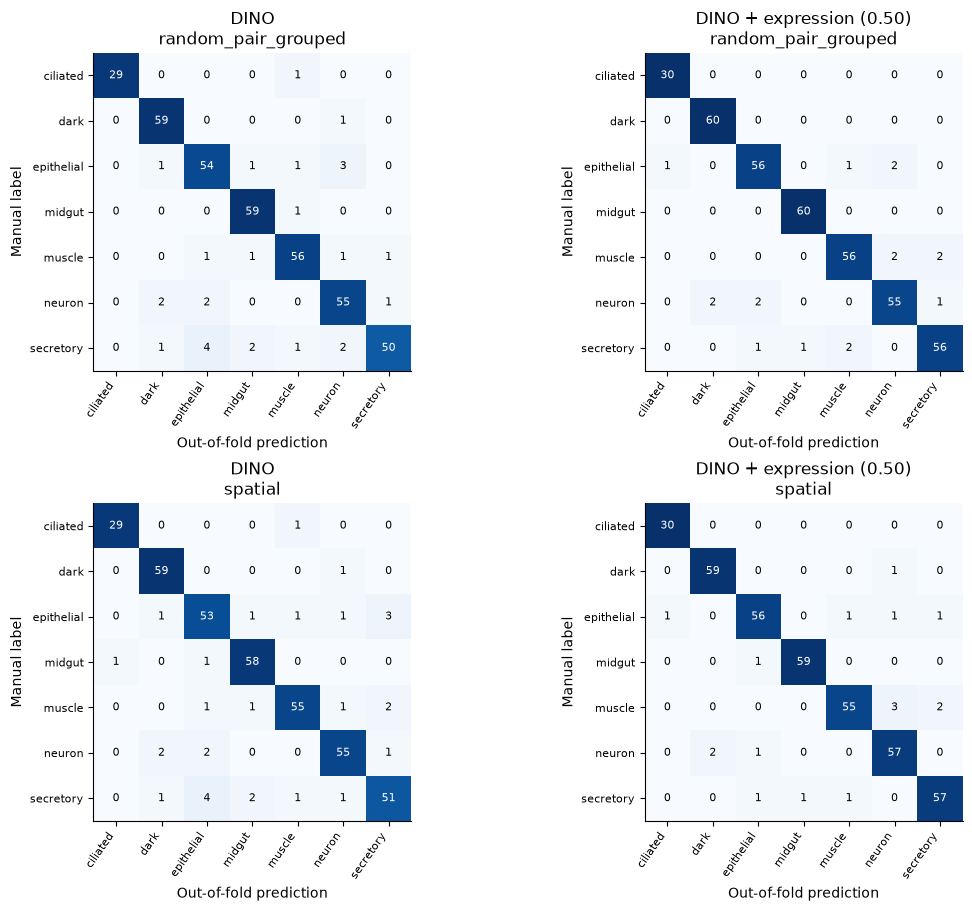

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

symmetry = pd.read_csv(CELL_TABLE_ROOT / 'symmetric_cells.tsv', sep='\t', dtype={'label_id': str})
symmetry['label_id'] = exact_ids(symmetry.label_id)
symmetry = symmetry.loc[symmetry.label_id > 0].copy()  # Background ID 0 occurs six times in this source.
assert symmetry.label_id.is_unique
symmetry = symmetry.set_index('label_id').reindex(ids)
pair_groups = np.asarray([f'pair:{int(pair)}' if pd.notna(pair) and pair > 0 else f'cell:{cell}'
                         for cell, pair in zip(ids, symmetry.pair_index)])
spatial_regions = KMeans(n_clusters=SPATIAL_REGIONS, n_init=20, random_state=SEED).fit_predict(XYZ)
save_table(pd.DataFrame({'cell_id': ids, 'nucleus_id': mapping.loc[ids, 'nucleus_id'],
                        'x': XYZ[:, 0], 'y': XYZ[:, 1], 'z': XYZ[:, 2],
                        'spatial_region': spatial_regions, 'pair_group': pair_groups}), 'spatial_and_pair_groups')

annotated_positions = np.flatnonzero(annotated)
classification_splits = {
    'random_pair_grouped': list(StratifiedGroupKFold(n_splits=CLASSIFIER_FOLDS, shuffle=True,
        random_state=SEED).split(np.zeros((len(truth), 1)), truth, groups=pair_groups[annotated])),
    'spatial': list(GroupKFold(n_splits=SPATIAL_FOLDS).split(
        np.zeros((len(truth), 1)), truth, groups=spatial_regions[annotated])),
}
fold_rows = []
for scheme, splits in classification_splits.items():
    for fold, (tr, te) in enumerate(splits):
        assert not set(tr) & set(te)
        if scheme == 'random_pair_grouped':
            assert not set(pair_groups[annotated][tr]) & set(pair_groups[annotated][te])
        else:
            assert not set(spatial_regions[annotated][tr]) & set(spatial_regions[annotated][te])
        shared_pairs = set(pair_groups[annotated][tr]) & set(pair_groups[annotated][te])
        for local in te:
            pos = annotated_positions[local]
            fold_rows.append({'scheme': scheme, 'fold': fold, 'cell_id': int(ids[pos]),
                'nucleus_id': int(mapping.loc[ids[pos], 'nucleus_id']), 'manual_type': truth[local],
                'spatial_region': int(spatial_regions[pos]),
                'train_missing_classes': ', '.join(sorted(set(truth) - set(truth[tr]))),
                'bilateral_groups_crossing_fold': len(shared_pairs)})
classification_fold_table = pd.DataFrame(fold_rows)
save_table(classification_fold_table, 'classification_folds')
print('Spatial folds with cross-fold bilateral groups are explicitly counted; pair-grouped CV is the paired-cell control.')
display(classification_fold_table.groupby(['scheme', 'fold']).agg(
    test_cells=('cell_id', 'size'), shared_bilateral_groups=('bilateral_groups_crossing_fold', 'max')))

class_rows, class_predictions, class_oof = [], [], {}
for scheme, splits in classification_splits.items():
    for name, recipe in representations.items():
        X = recipe['X'][annotated]
        predicted = np.empty(len(truth), dtype=object)
        for fold, (tr, te) in enumerate(splits):
            steps = [BalancedBlocks(recipe['sizes'], recipe['weights'], STANDARDIZE_EACH_FEATURE)]
            if CLASSIFIER_USE_PCA:
                steps.append(PCA(n_components=min(PCA_COMPONENTS, len(tr)-1, X.shape[1]),
                                 svd_solver='randomized', random_state=SEED))
            steps.append(LogisticRegression(C=LOGISTIC_C, class_weight='balanced', max_iter=2500))
            estimator = make_pipeline(*steps)
            estimator.fit(X[tr], truth[tr])
            predicted[te] = estimator.predict(X[te])
            for local, label in zip(te, predicted[te]):
                pos = annotated_positions[local]
                class_predictions.append({'scheme': scheme, 'representation': name, 'fold': fold,
                    'cell_id': int(ids[pos]), 'nucleus_id': int(mapping.loc[ids[pos], 'nucleus_id']),
                    'observed_manual_type': truth[local], 'predicted_type': label})
        class_oof[scheme, name] = predicted
        class_rows.append({'scheme': scheme, 'representation': name, 'objects': len(truth),
            'balanced_accuracy': balanced_accuracy_score(truth, predicted),
            'macro_f1': f1_score(truth, predicted, average='macro', zero_division=0)})
class_scores = pd.DataFrame(class_rows)
save_table(class_scores, 'manual_classification_scores')
save_table(pd.DataFrame(class_predictions), 'manual_classification_out_of_fold_predictions')
display(class_scores.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for row, scheme in enumerate(classification_splits):
    for col, name in enumerate(['DINO', PRIMARY_DINO_JOINT]):
        cm = confusion_matrix(truth, class_oof[scheme, name], labels=manual_order)
        proportion = cm / cm.sum(axis=1, keepdims=True)
        ax = axes[row, col]
        ax.imshow(proportion, cmap='Blues', vmin=0, vmax=1)
        for a, b in np.ndindex(cm.shape):
            ax.text(b, a, str(cm[a, b]), ha='center', va='center', fontsize=8,
                    color='white' if proportion[a, b] > .55 else 'black')
        ax.set_xticks(range(len(manual_order)), manual_order, rotation=55, ha='right', fontsize=8)
        ax.set_yticks(range(len(manual_order)), manual_order, fontsize=8)
        ax.set(title=f'{name}\n{scheme}', xlabel='Out-of-fold prediction', ylabel='Manual label')
save_figure(fig, 'manual_classification_confusion_matrices')

## 6. How much structure is shared? Three complementary questions

**Geometry:** linear centered kernel alignment (CKA) compares which pairs of cells look similar in morphology and in expression. It is not a percentage of “shared biological information.” We compare it against global row permutations and permutations restricted to coarse spatial regions. The latter preserve some anatomical structure, but cells are not perfectly exchangeable within regions: treat these as sensitivity controls, not a proof of causation or exact spatial significance. [CKA method](https://proceedings.mlr.press/v97/kornblith19a.html).

**Marginal dependence:** a k-nearest-neighbor MI estimator can screen each morphology PC against one binary gene. Results below are in bits; they are coordinate-dependent, biased at finite sample size, and cannot be added to obtain vector-level MI. A single shuffle is a diagnostic baseline, not a multiple-testing-corrected significance test. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html).

**Predictability:** out-of-fold log-loss improvement over a prevalence-only predictor measures useful predictive information from morphology. It is related to the entropy definition of MI but is not an exact MI estimate; a weak/misspecified model, spatial shifts and finite samples can make it negative. Gene prediction in the next section is the most directly actionable test.

Prespecified targets: ['Elav (XLOC-001549)', 'ncald (XLOC-040379)', 'pkd1 (XLOC-027897)', 'phc2 (XLOC-011941)', 'gata123 (XLOC-013055)', 'prox (XLOC-021539)', 'vglut (XLOC-008985)', 'Mef2c (XLOC-000048)']


,representation,control,cells,observed_CKA,null_mean,null_95th_percentile,permutation_rank_exploratory
0,DINO,global_shuffle,5000,0.1947,0.0020,0.0025,0.01
1,DINO,within_spatial_region_shuffle,5000,0.1947,0.0226,0.0253,0.01
2,MorphoFeatures,global_shuffle,5000,0.3016,0.0070,0.0073,0.01
3,MorphoFeatures,within_spatial_region_shuffle,5000,0.3016,0.0600,0.0630,0.01


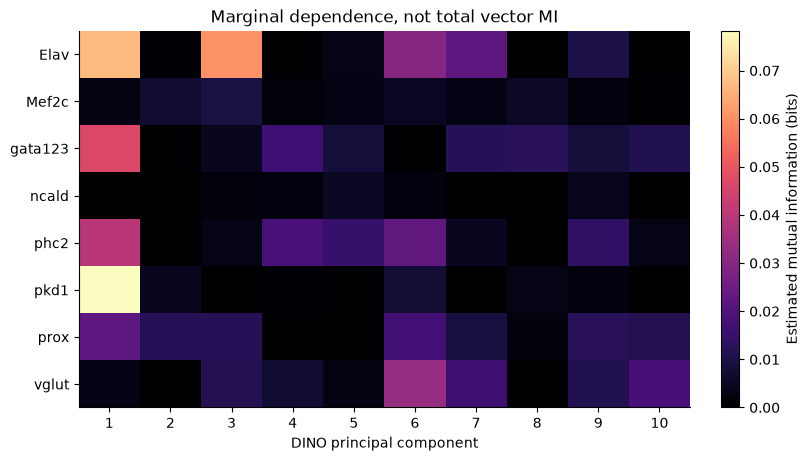

In [ ]:
def resolve_gene_targets(names):
    eligible = gene_qc.index[gene_qc.usable_prediction_target].tolist()
    if names is None:
        return eligible
    result = []
    for name in names:
        matches = [name] if name in gene_qc.index else gene_qc.index[
            gene_qc.vis_name.astype(str).str.casefold() == name.casefold()].tolist()
        if len(matches) != 1:
            raise ValueError(f'{name}: expected one XLOC match; found {matches}. Select an explicit XLOC ID.')
        if matches[0] not in eligible:
            print('Skipping rare/constant target:', name, matches[0])
        elif matches[0] not in result:
            result.append(matches[0])
    return result

gene_ids = resolve_gene_targets(TARGET_GENE_NAMES)
assert gene_ids, 'No eligible prediction targets.'
gene_columns = expression_nuclei.columns.get_indexer(gene_ids)
gene_display = [f'{gene_qc.loc[g, "vis_name"]} ({g})' for g in gene_ids]
print('Prespecified targets:', gene_display)

rng = np.random.default_rng(SEED)
MAX_SIMILARITY_CELLS = 5000
similarity_rows = np.sort(rng.choice(len(ids), min(MAX_SIMILARITY_CELLS, len(ids)), replace=False))
similarity_regions = spatial_regions[similarity_rows]
save_table(pd.DataFrame({'cell_id': ids[similarity_rows], 'spatial_region': similarity_regions}), 'similarity_cohort')
def centered_gram(X):
    X = X - X.mean(axis=0)
    return X @ X.T

gene_gram = centered_gram(transformed['Expression'][similarity_rows])
similarity_results, similarity_nulls = [], []
for name in ('DINO', 'MorphoFeatures'):
    image_gram = centered_gram(transformed[name][similarity_rows])
    denominator = np.linalg.norm(image_gram) * np.linalg.norm(gene_gram)
    observed = float(np.sum(image_gram * gene_gram) / denominator)
    for null_name in ('global_shuffle', 'within_spatial_region_shuffle'):
        perm_rng = np.random.default_rng(SEED)
        null = []
        for repetition in range(PERMUTATIONS):
            perm = np.arange(len(similarity_rows))
            if null_name == 'global_shuffle':
                perm_rng.shuffle(perm)
            else:
                for region in np.unique(similarity_regions):
                    positions = np.flatnonzero(similarity_regions == region)
                    perm[positions] = perm_rng.permutation(positions)
            value = float(np.sum(image_gram * gene_gram[np.ix_(perm, perm)]) / denominator)
            null.append(value)
            similarity_nulls.append({'representation': name, 'control': null_name,
                                     'permutation': repetition, 'CKA': value})
        similarity_results.append({'representation': name, 'control': null_name,
            'cells': len(similarity_rows), 'observed_CKA': observed,
            'null_mean': np.mean(null), 'null_95th_percentile': np.quantile(null, .95),
            'permutation_rank_exploratory': (1 + np.sum(np.asarray(null) >= observed)) / (1 + PERMUTATIONS)})
cka_scores = pd.DataFrame(similarity_results)
save_table(cka_scores, 'cka_similarity_controls')
save_table(pd.DataFrame(similarity_nulls), 'cka_permutation_values')
display(cka_scores.round(4))

mi_table = pd.DataFrame()
if RUN_MI_SCREEN:
    from sklearn.feature_selection import mutual_info_classif
    mi_rows = []
    screen = pca_spaces['DINO'][similarity_rows, :10]
    for gene, column in zip(gene_ids, gene_columns):
        target = E[similarity_rows, column].astype(int)
        if len(np.unique(target)) < 2:
            continue
        observed = mutual_info_classif(screen, target, discrete_features=False, n_neighbors=5, random_state=SEED) / np.log(2)
        shuffled = mutual_info_classif(screen, np.random.default_rng(SEED).permutation(target),
            discrete_features=False, n_neighbors=5, random_state=SEED) / np.log(2)
        for pc, value in enumerate(observed):
            mi_rows.append({'XLOC': gene, 'gene': gene_qc.loc[gene, 'vis_name'], 'PC': pc+1,
                            'MI_bits': value, 'one_shuffle_MI_bits': shuffled[pc]})
    mi_table = pd.DataFrame(mi_rows)
    save_table(mi_table, 'marginal_pc_gene_mi_descriptive')
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    heat = mi_table.pivot(index='gene', columns='PC', values='MI_bits')
    image = ax.imshow(heat, cmap='magma', aspect='auto', vmin=0)
    ax.set_xticks(range(heat.shape[1]), heat.columns)
    ax.set_yticks(range(len(heat)), heat.index)
    ax.set(xlabel='DINO principal component', title='Marginal dependence, not total vector MI')
    fig.colorbar(image, ax=ax, label='Estimated mutual information (bits)')
    save_figure(fig, 'marginal_gene_mi')

## 7. Predict the observed gene calls using morphology alone

For every selected gene, compare a training-prevalence baseline, a **position-only** nearest-neighbor model, DINO, original MorphoFeatures, DINO plus position, and a shuffled-training-label DINO control. The gene call being predicted is **never an input** to any of these models. The target is the available **thresholded spatial call**, not molecule abundance or a causal regulatory program.

Each fold refits morphology centering/L2 normalization and PCA on training cells. DINO/MorphoFeatures use logistic regression **without balanced class weighting**, so prevalence and log-loss retain their usual interpretation. DINO+position adds a fixed random Fourier representation of training-standardized coordinates. The coordinate baseline uses 50 nearby training cells. These are simple prespecified baselines, not an exhaustive search for the best model.

Report **average precision (AP)** against the positive fraction, ROC-AUC, Brier score and log loss. AP is especially useful for sparse positives. A prettier UMAP or high overall accuracy from predicting every cell negative is not success. [AP definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

Random folds keep known pairs together. Spatial folds use the same coordinate groups as above. Inspect folds with absent positive/negative training examples; the code uses a training-prior fallback and records them. Spatial blocking has boundary and bilateral-pair limitations, and severe anatomical shifts may make some genes impossible to learn from a given training fold. Multiple animals and buffered anatomical splits would provide stronger validation. [Why spatial validation matters](https://doi.org/10.1111/ecog.02881).

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_approximation import RBFSampler

def random_group_splits(groups, folds, seed):
    unique = np.unique(groups)
    rng = np.random.default_rng(seed)
    rng.shuffle(unique)
    for test_groups in np.array_split(unique, folds):
        test = np.flatnonzero(np.isin(groups, test_groups))
        train = np.flatnonzero(~np.isin(groups, test_groups))
        yield train, test

gene_splits = {
    'random_pair_grouped': list(random_group_splits(pair_groups, GENE_RANDOM_FOLDS, SEED)),
    'spatial': list(GroupKFold(n_splits=SPATIAL_FOLDS).split(XYZ, groups=spatial_regions)),
}
Y = E[:, gene_columns].astype(np.int8)
model_names = ('Prior', 'Position', 'DINO', 'MorphoFeatures', 'DINO + position', 'DINO shuffled control')
gene_oof, gene_fold_assignments, gene_fold_diagnostics = {}, {}, []
gene_metric_rows = []
if RUN_GENE_PREDICTION:
    for scheme, splits in gene_splits.items():
        predictions = {name: np.full(Y.shape, np.nan) for name in model_names}
        fold_ids = np.full(len(ids), -1, dtype=int)
        for fold, (tr, te) in enumerate(splits):
            print(f'Gene prediction: {scheme}, fold {fold+1}/{len(splits)}', flush=True)
            assert not set(tr) & set(te)
            if scheme == 'random_pair_grouped':
                assert not set(pair_groups[tr]) & set(pair_groups[te])
            else:
                assert not set(spatial_regions[tr]) & set(spatial_regions[te])
            fold_ids[te] = fold
            prior = (Y[tr].sum(axis=0) + 1) / (len(tr) + 2)  # Finite even with no positives.
            predictions['Prior'][te] = prior
            position_model = KNeighborsRegressor(n_neighbors=min(50, len(tr)), weights='distance')
            predictions['Position'][te] = position_model.fit(XYZ[tr], Y[tr]).predict(XYZ[te])
            features = {}
            for name, source in [('DINO', D), ('MorphoFeatures', M)]:
                prep = make_pipeline(BalancedBlocks((source.shape[1],), (1.0,), STANDARDIZE_EACH_FEATURE),
                    PCA(n_components=min(GENE_PCA_COMPONENTS, source.shape[1], len(tr)-1),
                        svd_solver='randomized', random_state=SEED))
                features[name] = (prep.fit_transform(source[tr]), prep.transform(source[te]))
            location = make_pipeline(StandardScaler(), RBFSampler(gamma=.25, n_components=64, random_state=SEED))
            pos_train, pos_test = location.fit_transform(XYZ[tr]), location.transform(XYZ[te])
            features['DINO + position'] = (np.column_stack([features['DINO'][0], pos_train]),
                                          np.column_stack([features['DINO'][1], pos_test]))
            features['DINO shuffled control'] = features['DINO']
            permutation = np.random.default_rng(SEED + fold).permutation(len(tr))
            for j, gene in enumerate(gene_ids):
                train_positive = int(Y[tr, j].sum())
                for name, (train_X, test_X) in features.items():
                    train_y = Y[tr, j]
                    if name == 'DINO shuffled control':
                        train_y = train_y[permutation]
                    absent_class = np.unique(train_y).size < 2
                    if absent_class:
                        predictions[name][te, j] = prior[j]
                    else:
                        model = LogisticRegression(C=LOGISTIC_C, class_weight=None, max_iter=2000)
                        model.fit(train_X, train_y)
                        predictions[name][te, j] = model.predict_proba(test_X)[:, list(model.classes_).index(1)]
                    gene_fold_diagnostics.append({'scheme': scheme, 'fold': fold, 'XLOC': gene,
                        'model': name, 'train_positive': train_positive, 'train_negative': len(tr)-train_positive,
                        'test_positive': int(Y[te, j].sum()), 'test_negative': int(len(te)-Y[te, j].sum()),
                        'used_prior_fallback': absent_class,
                        'cross_fold_bilateral_groups': len(set(pair_groups[tr]) & set(pair_groups[te]))})
        assert np.all(fold_ids >= 0)
        gene_fold_assignments[scheme] = fold_ids
        gene_oof[scheme] = predictions
        for j, gene in enumerate(gene_ids):
            prevalence = Y[:, j].mean()
            prior_loss = log_loss(Y[:, j], np.clip(predictions['Prior'][:, j], 1e-6, 1-1e-6), labels=[0, 1])
            for name, values in predictions.items():
                assert np.isfinite(values).all()
                p = np.clip(values[:, j], 1e-6, 1-1e-6)
                loss = log_loss(Y[:, j], p, labels=[0, 1])
                ap = average_precision_score(Y[:, j], p)
                gene_metric_rows.append({'scheme': scheme, 'model': name, 'XLOC': gene,
                    'gene': gene_qc.loc[gene, 'vis_name'], 'objects': len(ids), 'prevalence': prevalence,
                    'average_precision': ap, 'AP_above_prevalence': ap-prevalence,
                    'ROC_AUC': roc_auc_score(Y[:, j], p), 'Brier_score': brier_score_loss(Y[:, j], p),
                    'log_loss_nats': loss, 'log_loss_gain_bits_vs_prior': (prior_loss-loss)/np.log(2)})
    gene_scores = pd.DataFrame(gene_metric_rows)
    save_table(gene_scores, 'gene_prediction_scores')
    save_table(pd.DataFrame(gene_fold_diagnostics), 'gene_prediction_fold_diagnostics')
    arrays = {'label_ids': ids.to_numpy(dtype=np.int64), 'nucleus_ids': mapping.loc[ids, 'nucleus_id'].to_numpy(dtype=np.int64),
              'gene_ids': np.asarray(gene_ids, dtype=str), 'observed_binary': Y}
    for scheme, values in gene_oof.items():
        arrays[scheme + '__fold'] = gene_fold_assignments[scheme]
        for model, predicted in values.items():
            arrays[scheme + '__' + slug(model)] = predicted.astype(np.float32)
    np.savez_compressed(OUT / 'vectors/gene_predictions_out_of_fold.npz', **arrays)
    display(gene_scores.groupby(['scheme', 'model'])[
        ['average_precision', 'AP_above_prevalence', 'ROC_AUC', 'log_loss_gain_bits_vs_prior']].mean().round(3))
else:
    gene_scores = pd.DataFrame()
    print('Gene prediction disabled; the remaining sections still work.')

Gene prediction: random_pair_grouped, fold 1/3


Gene prediction: random_pair_grouped, fold 2/3
Gene prediction: random_pair_grouped, fold 3/3
Gene prediction: spatial, fold 1/4
Gene prediction: spatial, fold 2/4
Gene prediction: spatial, fold 3/4
Gene prediction: spatial, fold 4/4


average_precision  \
scheme              model                                      
random_pair_grouped DINO                               0.474   
                    DINO + position                    0.590   
                    DINO shuffled control              0.267   
                    MorphoFeatures                     0.473   
                    Position                           0.680   
                    Prior                              0.259   
spatial             DINO                               0.437   
                    DINO + position                    0.493   
                    DINO shuffled control              0.242   
                    MorphoFeatures                     0.438   
                    Position                           0.435   
                    Prior                              0.235   

                                           AP_above_prevalence  ROC_AUC  \
scheme              model                                                 
random_pair_grouped DINO                                 0.212    0.749   
                    DINO + position                      0.329    0.820   
                    DINO shuffled control                0.006    0.502   
                    MorphoFeatures                       0.212    0.749   
                    Position                             0.419    0.880   
                    Prior                               -0.002    0.492   
spatial             DINO                                 0.176    0.717   
                    DINO + position                      0.232    0.745   
                    DINO shuffled control               -0.020    0.458   
                    MorphoFeatures                       0.177    0.721   
                    Position                             0.174    0.680   
                    Prior                               -0.026    0.420   

                                           log_loss_gain_bits_vs_prior  
scheme              model                                               
random_pair_grouped DINO                                         0.115  
                    DINO + position                              0.204  
                    DINO shuffled control                       -0.003  
                    MorphoFeatures                               0.115  
                    Position                                     0.267  
                    Prior                                        0.000  
spatial             DINO                                         0.100  
                    DINO + position                              0.096  
                    DINO shuffled control                       -0.002  
                    MorphoFeatures                               0.102  
                    Position                                    -0.106  
                    Prior                                        0.000

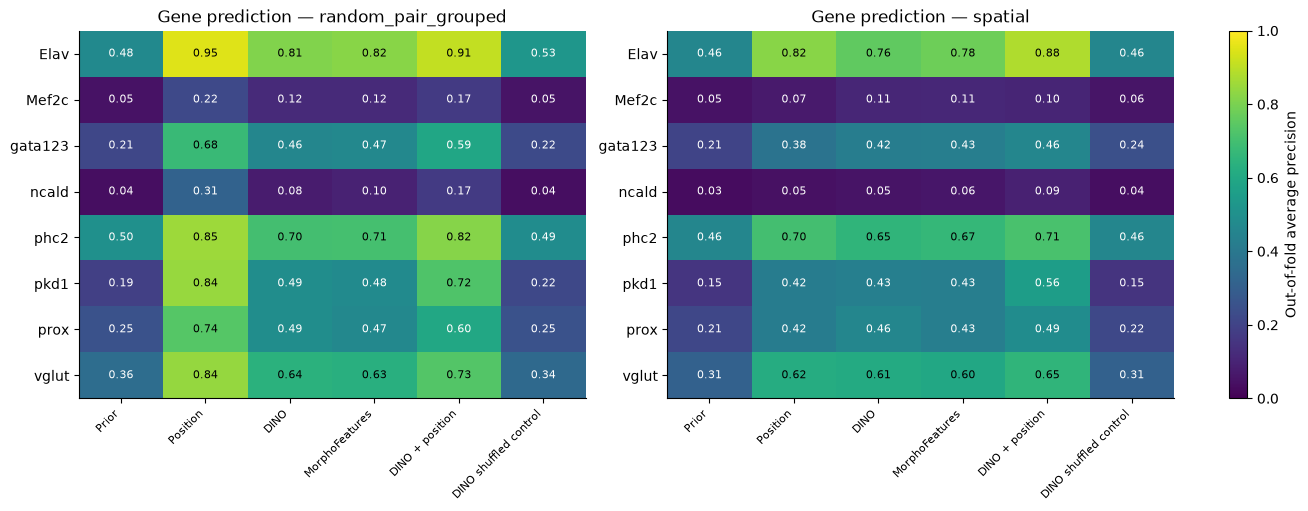

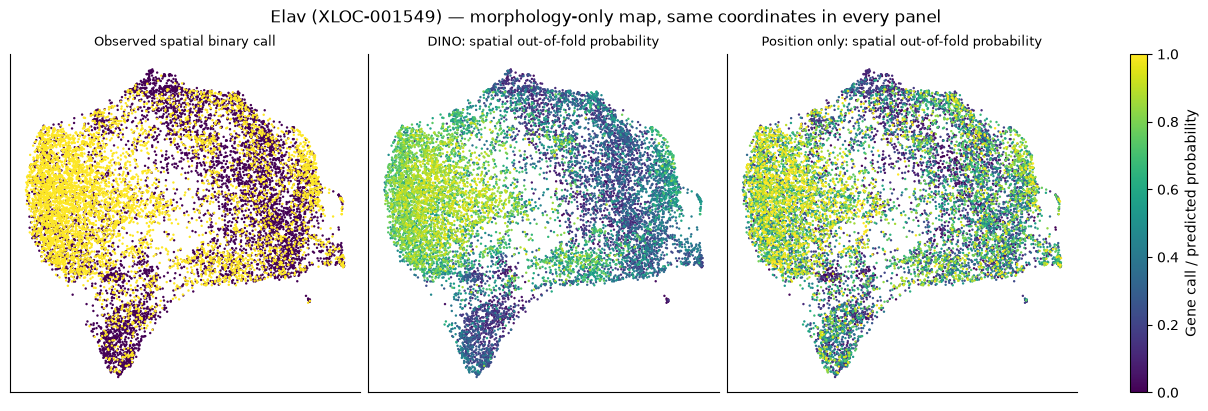

In [ ]:
if not gene_scores.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
    model_order = ['Prior', 'Position', 'DINO', 'MorphoFeatures', 'DINO + position', 'DINO shuffled control']
    for ax, scheme in zip(axes, gene_splits):
        matrix = gene_scores[gene_scores.scheme.eq(scheme)].pivot(index='gene', columns='model', values='average_precision')[model_order]
        im = ax.imshow(matrix, cmap='viridis', vmin=0, vmax=1, aspect='auto')
        ax.set_xticks(range(len(model_order)), model_order, rotation=45, ha='right', fontsize=8)
        ax.set_yticks(range(len(matrix)), matrix.index)
        ax.set_title(f'Gene prediction — {scheme}')
        for a, b in np.ndindex(matrix.shape):
            ax.text(b, a, f'{matrix.iloc[a,b]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if matrix.iloc[a,b] < .6 else 'black')
    fig.colorbar(im, ax=axes, label='Out-of-fold average precision')
    save_figure(fig, 'gene_prediction_average_precision')

    if 'DINO' in umap_spaces:
        xy = umap_spaces['DINO']
        gene = gene_ids[0]
        fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
        for ax, values, title in [
            (axes[0], Y[:, 0], 'Observed spatial binary call'),
            (axes[1], gene_oof['spatial']['DINO'][:, 0], 'DINO: spatial out-of-fold probability'),
            (axes[2], gene_oof['spatial']['Position'][:, 0], 'Position only: spatial out-of-fold probability')]:
            order = np.argsort(values)
            im = ax.scatter(xy[order, 0], xy[order, 1], c=values[order], vmin=0, vmax=1, cmap='viridis',
                            s=3, linewidths=0, rasterized=True)
            ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(gene_display[0] + ' — morphology-only map, same coordinates in every panel')
        fig.colorbar(im, ax=axes, label='Gene call / predicted probability')
        save_figure(fig, 'observed_vs_predicted_gene_on_dino_map')
    preview = pd.DataFrame({'label_id': mapping.loc[ids, 'nucleus_id'].to_numpy(), 'cell_id': ids,
                            'observed_' + gene_ids[0]: Y[:, 0]})
    for name in model_names:
        preview['predicted_' + slug(name)] = gene_oof['spatial'][name][:, 0]
    save_table(preview, 'first_gene_predictions_nucleus_namespace')

## 8. What these experiments can and cannot establish

| Observation | Useful interpretation | Check before a stronger claim |
|---|---|---|
| Fusion improves manual-label CV | Expression complements these morphology features for this annotation task. | Confirm the weight/model on new data; inspect class-specific errors and whether labels themselves used expression. |
| Fusion looks cleaner but CV is unchanged/worse | Molecular and morphological organization may disagree; the weighting or noise level may also be unsuitable. | Compare expression alone, individual classes, nearby cells, and held-out tasks. Do not optimize plot appearance. |
| scLocator agreement increases with expression weight | Expected: the classifier and joint vector reuse the same molecular input. | This is not independent validation. Use manual labels or separately held-out molecular measurements. |
| Morphology predicts genes better than a prevalence model | There is predictive association with the available spatial calls. | Compare position, shuffled labels, spatial folds, registration quality, and class/size covariates. |
| Position performs as well as morphology | Anatomical location may explain much of the relationship. | Test a new animal, within anatomical regions/types, and with buffers between train and test cells. |
| DINO+position improves over position alone | Morphology may add information at the modeled spatial resolution. | This is not a causal effect; classifier capacity and imperfect spatial controls can also matter. |
| Fine scLocator confidence is lower than broad confidence | More categories divide score mass; similar reference profiles may be hard to distinguish. | Use score entropy/top alternatives and aggregate related types before assigning very precise identities. |

**A sensible order for further work**

1. Ask the previous analyst for the two YAML configs named in the logs, scLocator code/version, gene-symbol↔XLOC mapping tables, original continuous spatial tables, per-source gene-selection/precedence rules, thresholds, registration provenance and QC split details. Specifically resolve warnings such as `ropsin_wrong` and unmapped aliases; an alias warning is not proof the gene is entirely absent via another source.
2. Keep the binary table as the reproducible baseline. Recover continuous spatial measurements before trying regression, threshold sensitivity or uncertainty-aware fusion. Do not substitute the RNA-reference `norm_expr` matrix for missing measurements in EM cells.
3. Run the prespecified fusion weights and compare stable biological annotations, gene holdouts and spatial validation. For “predict a gene using other genes + morphology,” explicitly remove that gene (and consider correlated marker blocks) from fusion and fit preprocessing inside each fold. That is a different experiment from morphology-only prediction above.
4. Try a learned shared representation only after these baselines: regularized CCA/PLS or multi-view factor models can separate shared and modality-specific variation, but fitting and dimensionality selection require held-out cells. A high training canonical correlation in high dimensions is not evidence of transferable biology.
5. Consider **weighted nearest-neighbor (WNN)** integration when each cell should choose how much to trust each modality. WNN combines neighborhood graphs; it does not automatically give a fixed concatenated vector, and it cannot repair incorrect cell matching or registered signal. This notebook deliberately exports a transparent fixed vector first. [Official WNN workflow](https://satijalab.org/seurat/articles/weighted_nearest_neighbor_analysis.html).
6. For new unlabeled EM data, train a morphology→gene-call model using only the morphology block. Predicted expression concatenated back onto the same morphology is a supervised re-expression of existing information, **not a new independent modality**. To assess whether it helps classification, generate training predictions by cross-fitting and keep every label/feature transformation outside its test fold.
7. Validate across independent animals and eventually species, with compatible embedding recipes and gene orthology. The six RNA-reference sequencing batches are not six paired EM specimens. A single-animal success does not establish cross-species expression prediction.

The original MorphoFeatures method combines complementary morphology representations; adding this molecular block follows the general idea but defines a new analysis and a different information source. [Original paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9934868/).

The missing original run configs named in the logs are `experiments/broad_types/config_broad_types.yaml` and `experiments/curated_high_res_annotations/config_highres_annotations.yaml`. Recover these from the previous analyst before trying to reproduce upstream gene thresholds or source mixing.

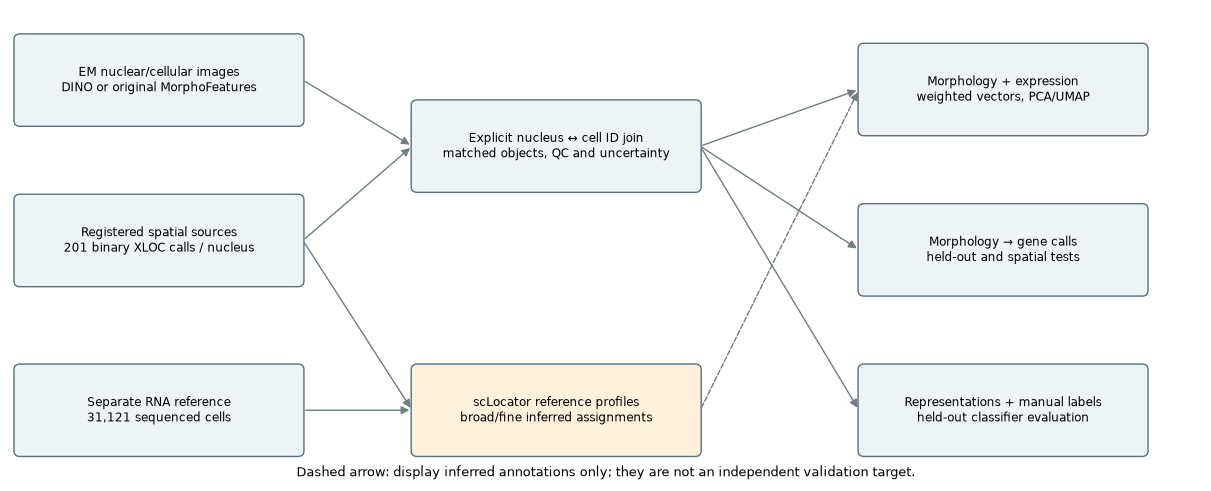

Saved findings: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/morphology_expression/20261002-163056/findings.md
Saved provenance: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/morphology_expression/20261002-163056/provenance.json
Saved vectors: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/morphology_expression/20261002-163056/vectors
Saved figures: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/morphology_expression/20261002-163056/figures


In [ ]:
# A compact provenance figure, suitable for sharing with collaborators.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
ax.set(xlim=(0, 12), ylim=(0, 5)); ax.axis('off')
nodes = {
    'raw': (1.5, 4.25, 'EM nuclear/cellular images\nDINO or original MorphoFeatures'),
    'spatial': (1.5, 2.55, 'Registered spatial sources\n201 binary XLOC calls / nucleus'),
    'rna': (1.5, .75, 'Separate RNA reference\n31,121 sequenced cells'),
    'join': (5.5, 3.55, 'Explicit nucleus ↔ cell ID join\nmatched objects, QC and uncertainty'),
    'sc': (5.5, .75, 'scLocator reference profiles\nbroad/fine inferred assignments'),
    'joint': (10, 4.15, 'Morphology + expression\nweighted vectors, PCA/UMAP'),
    'predict': (10, 2.45, 'Morphology → gene calls\nheld-out and spatial tests'),
    'manual': (10, .75, 'Representations + manual labels\nheld-out classifier evaluation'),
}
for key, (x, y, label) in nodes.items():
    ax.add_patch(FancyBboxPatch((x-1.4, y-.43), 2.8, .86, boxstyle='round,pad=.06',
                              facecolor='#eef3f6' if key != 'sc' else '#fff1dc', edgecolor='#537185'))
    ax.text(x, y, label, ha='center', va='center', fontsize=8.5)
for start, end in [('raw','join'), ('spatial','join'), ('rna','sc'), ('spatial','sc'),
                   ('join','joint'), ('join','predict'), ('join','manual'), ('sc','joint')]:
    x1,y1,_=nodes[start]; x2,y2,_=nodes[end]
    ax.add_patch(FancyArrowPatch((x1+1.45,y1),(x2-1.45,y2),arrowstyle='-|>',mutation_scale=12,
                                linewidth=1,color='#6f7d84',linestyle='--' if start=='sc' else '-'))
ax.text(6, .05, 'Dashed arrow: display inferred annotations only; they are not an independent validation target.',
        ha='center', fontsize=9)
save_figure(fig, 'data_provenance')

source_paths = [*expression_files, DINO_PATH, DINO_NOTEBOOK_PATH, MORPHO_PATH, MANUAL_PATH,
               CELL_TABLE_ROOT / 'cells_to_nuclei.tsv', CELL_TABLE_ROOT / 'default.tsv',
               CELL_TABLE_ROOT / 'symmetric_cells.tsv', NUCLEUS_TABLE_PATH, REPO / 'joint_projection_test.ipynb']
for folder in runs.values():
    source_paths.extend([folder / 'cluster_prob/cluster_probability.tsv', folder / 'sclocator.log',
                         folder / 'expression_profiles/profiles_dictionary.pkl'])
fingerprints = []
for path in source_paths:
    fingerprints.append({'path': str(path), 'bytes': path.stat().st_size,
                         'sha256': sha256_file(path)})
for folder in runs.values():
    for path in (folder / 'atlas').glob('*.h5ad'):
        fingerprints.append({'path': str(path), 'bytes': path.stat().st_size,
                             'mtime_ns': path.stat().st_mtime_ns,
                             'fingerprint_note': 'Metadata only; not a full 6 GB checksum. Binary X/obs/var equality checked separately.'})
config_names = ['SEED','SPATIAL_POSITION_SOURCE','EXCLUDE_ALL_ZERO_EXPRESSION','EXPRESSION_WEIGHTS','STANDARDIZE_EACH_FEATURE',
    'PCA_COMPONENTS','CLASSIFIER_USE_PCA','UMAP_NEIGHBORS','UMAP_MIN_DIST','RUN_UMAP','CLUSTER_COUNTS','SPATIAL_REGIONS',
    'CLASSIFIER_FOLDS','SPATIAL_FOLDS','LOGISTIC_C','MAX_SIMILARITY_CELLS','PERMUTATIONS',
    'TARGET_GENE_NAMES','MIN_GENE_CLASS_SIZE','GENE_RANDOM_FOLDS','GENE_PCA_COMPONENTS',
    'RUN_GENE_PREDICTION','RUN_MI_SCREEN','CPU_THREADS']
write_json({'schema': 'morphology_expression_exploration.v1', 'run_id': RUN_ID,
    'created': datetime.now(ZoneInfo('Europe/Berlin')).isoformat(), 'python': platform.python_version(),
    'versions': versions, 'settings': {name: globals()[name] for name in config_names},
    'sources': fingerprints, 'input_id_namespaces': {'expression': 'nucleus', 'embeddings': 'cell', 'manual_labels': 'cell'},
    'cells': len(ids), 'manual_labels': int(annotated.sum()), 'expression_features': E.shape[1],
    'output_feature_namespaces': 'vectors/*.npz label_ids are cell IDs; nucleus_ids are separate',
    'missing_upstream_provenance': ['scLocator configs/version','spatial thresholds and source precedence',
                                    'original continuous spatial tables','QC validation split provenance'],
    'evaluation_limits': ['single EM specimen', 'scLocator labels are expression-derived',
                          'spatial groups have boundary and bilateral-pair limitations',
                          'fixed hyperparameters; no independent recipe-selection confirmation set']}, OUT / 'provenance.json')

def markdown_table(frame):
    frame = frame.copy()
    for column in frame.select_dtypes('number'):
        frame[column] = frame[column].map(lambda value: f'{value:.3f}')
    header = '| ' + ' | '.join(map(str, frame.columns)) + ' |'
    separator = '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |'
    rows = ['| ' + ' | '.join(map(str, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join([header, separator, *rows])

report = [
    '# Morphology and spatial expression: findings',
    f'Generated from the tutorial notebook; run `{RUN_ID}`. All paths/settings and source fingerprints are in `provenance.json`.',
    '## Data relationships',
    'The three binary spatial expression files are identical: 11,382 nucleus IDs × 201 gene features, no missing values. '
    'The nonzero mapping gives 11,382 unique cell/nucleus pairs and matches both embedding datasets. '
    'Original MorphoFeatures contains 480 features plus a cell-ID column. DINO has 768 features. '
    'The draft used the L2-normalized transfer-reference copy; this analysis starts from its original frozen DINO vectors.',
    f'Analysis retained {len(ids):,} cells and {int(annotated.sum())} manual annotations. '
    'Five expression-empty nuclei (4000, 5500, 5502, 7765, 7767) and any other exclusions are recorded in the cohort audit. '
    'Tan / XLOC-019991 is constant zero. Training-constant features are removed inside each fitted block.',
    'The broad/fine folders share the same 31,121-cell 6-dpf RNA reference, six sequencing batches, and the same 201-gene binary X. '
    'There are 15 broad / 274 fine biological categories plus zero/autofluorescence synthetic profiles. '
    'The reference barcodes are not EM object IDs. Fine categories map unambiguously to broad categories in the saved reference.',
    f'Spatial controls use {SPATIAL_POSITION_SOURCE} anchors. The cell and nucleus anchor positions differ by '
    f'a median of {np.median(anchor_distance):.2f} and a 99th percentile of {np.quantile(anchor_distance,.99):.2f} '
    'in the common table coordinate units (published PlatyBrowser physical coordinates). '
    'The coordinate audit retains these displacements for inspection.',
    'The logs record smfish, prospr, muscle_ropsin and spinning_disk inputs. Source configs, continuous spatial measurements, '
    'thresholds, precedence between overlapping genes, model calibration and profile-QC split provenance are missing. '
    'Retain the exported scores without treating them as verified posterior correctness or held-out EM accuracy.',
    'The internal QC matrices are column-normalized; their diagonal means are 0.697 (broad) and 0.635 (fine), '
    'but the held-out/training status and axis definitions are unavailable. These are not comparable EM accuracy scores. '
    'Aggregating fine assignment scores to broad categories agrees with the separate broad winner for about 71% of the retained cells. '
    'Start with broad categories and soft scores; inspect fine annotations as additional hypotheses.',
    '## Manual-label classification',
    'Point estimates on identical folds. Weights/C/PCA dimensions were prespecified. Comparing several recipes is exploratory; '
    'do not select the best score and call it an unbiased final test result. Random folds group known bilateral pairs; '
    'spatial folds hold out coordinate regions and record cross-fold bilateral relationships.',
    markdown_table(class_scores),
    'Compare matched rows in this table. Small score differences on 390 labels do not establish statistical significance '
    'or generalization to another animal. The fixed 50-PC default retains different variance across modalities; '
    'test full-vector classification or other dimensions before attributing every difference to biological complementarity.',
    '## Shared representation structure',
    'CKA describes geometry, not a fraction of biological information or vector-level MI. Permutation ranks are exploratory '
    'and depend on exchangeability; within-region shuffles retain only coarse anatomy.',
    markdown_table(cka_scores),
]
if not gene_scores.empty:
    summary = gene_scores.groupby(['scheme','model'])[['average_precision','ROC_AUC','log_loss_gain_bits_vs_prior']].mean().reset_index()
    report += ['## Gene-call prediction',
        'Means below cover only the explicitly selected target panel, not the entire transcriptome. '
        'Gene-level prevalence/AP and fold diagnostics are exported separately. Position and shuffled controls are essential '
        'for interpreting morphology associations. These are predictions of registered binary spatial calls, not RNA molecule counts.',
        markdown_table(summary),
        'Compare spatial and random rows, especially position-only performance. Compare both AP and log loss: better '
        'ranking does not automatically mean better probabilities. Gene-specific scores can differ greatly; see '
        'tables/gene_prediction_scores.tsv. Results apply to these binary calls, not expression abundance or all genes.']
score_lookup = class_scores.set_index(['scheme', 'representation']).balanced_accuracy
observations = []
for scheme in classification_splits:
    before, after = score_lookup.loc[(scheme, 'DINO')], score_lookup.loc[(scheme, PRIMARY_DINO_JOINT)]
    observations.append(f'{scheme}: DINO balanced accuracy {before:.1%}; {PRIMARY_DINO_JOINT} {after:.1%} '
                        f'(difference {100*(after-before):+.2f} percentage points).')
if not gene_scores.empty:
    mean_ap = gene_scores.groupby(['scheme', 'model']).average_precision.mean()
    for scheme in gene_splits:
        observations.append(f'{scheme}: mean AP across {len(gene_ids)} targets — '
            + ', '.join(f'{model}: {mean_ap.loc[(scheme, model)]:.3f}' for model in ('DINO','Position','DINO + position')) + '.')
report += ['## Concrete comparisons in this execution', '\n\n'.join(observations)]
report += ['## Recommended next steps',
    'Recover the missing upstream configs and continuous measurements; inspect gene-specific results and spatial errors; '
    'compare prespecified fusion weights on independent annotations; extend the target panel; validate on another animal '
    'with consistent gene/embedding definitions. Consider regularized multi-view models or WNN only after these baselines.',
    '## Outputs and ID conventions',
    '`vectors/*.npz`: actual full high-dimensional vectors, label_ids=cell IDs and separate nucleus_ids; '
    '`gene_predictions_out_of_fold.npz`: per-model gene probabilities with both IDs and fold membership; '
    '`tables/`: cohort audit, gene dictionary, mapping warnings, annotations, folds, scores and coordinates; '
    '`figures/`: SVG and PNG plots; `models/`: numeric exploratory centering/scaling/PCA parameters. '
    'For a nucleus segmentation/MoBIE nucleus table use nucleus_ids as label_id, not the cell IDs. '
    'For cell segmentation use the cell IDs. Do not rename IDs without the saved bridge.',
    'Methodological references and interpretation details are in the tutorial notebook.']
(OUT / 'findings.md').write_text('\n\n'.join(report) + '\n')
print('Saved findings:', OUT / 'findings.md')
print('Saved provenance:', OUT / 'provenance.json')
print('Saved vectors:', OUT / 'vectors')
print('Saved figures:', OUT / 'figures')

## 9. Reading/exporting the results later

`findings.md` summarizes this executed run; `provenance.json` records versions, input fingerprints and settings. The NPZ files contain **actual high-dimensional combined vectors**, not PCA/UMAP coordinates. Every table or array that refers to an EM object retains a cell ID and/or its explicit nucleus lookup. For MoBIE or segmentation overlays, choose the ID namespace of the volume you are displaying.

The joint vectors are for cells with both observed modalities. The gene prediction file contains **out-of-fold** probabilities for the selected observed genes, with fold membership. It is not a fitted deployment model for another animal. To deploy, select hyperparameters without using the held-out test set, refit preprocessing and classifiers on the training cohort, save those fitted transforms, then apply them to equivalent morphology features of the new cells. Keep observed and predicted expression in separate columns.

Nothing here demonstrates new molecular information when a prediction derived from morphology is concatenated back to morphology. What it can provide is a useful supervised organization of morphology; test that benefit with cross-fitting.